# KPI2 회귀분석

## 모형 구성

| 번호 | 모형 | 변수 구성 |
|---|---|---|
| 1 | 모형 1 | `Y ~ T` |
| 2 | 모형 2 | `Y ~ T * (G + Q)` |
| 3 | 모형 3 | `Y ~ T * (G + Q + A)` |
| 4 | 모형 4 | `Y ~ T * (G + Q + A + W)` |
| 5 | 모형 4 + 월·요일·연도추세 | `Y ~ T * (G + Q + A + W) + M + D + L` |
| 6 | 모형 4 확장 | `Y ~ T * ((G + Q) * (A + W))` |
| 7 | 모형 4 확장 + 월·요일·연도추세 | `Y ~ T * ((G + Q) * (A + W)) + M + D + L` |

T=터미널, G=총톤수, Q=총작업량, A=특보유무, W=선택된 기상변수,
M=월 더미 11개, D=요일 더미 6개, L=접안연도−2021입니다.
`*`는 주효과와 상호작용을 함께 포함합니다. 전체 후보는 정확히 7개입니다.

시간변수는 5번·7번에만 터미널 공통 효과로 들어갑니다.
연도추세는 2021년=0, 2022년=1, 2023년=2, 2024년=3인 숫자 한 열입니다.

## 분석 기준

- 학습: 2021~2023년 접안 중 2024년 시작 전에 출항한 기록.
- 검증: 2024년 접안. 기존 결측치 삭제·경계 제외·변수 선택 기준 유지.
- 표준화·중심화와 기준 기상은 학습자료에서 결정합니다.
- 신뢰구간은 날짜 기준 HAC 28일·56일을 사용합니다.
- KPI·잔차·BP·White·VIF의 기본 평가 대상은 **7번 모형**입니다.

## 모형 평가 원칙

- 같은 2024년 검증 행에서 전체·항만·터미널·특보별 MAE, RMSE, 평균잔차를 비교합니다.
- **잔차 = 실제 체류시간 − 예측 체류시간**입니다. 양수는 과소예측, 음수는 과대예측입니다.
- 장기 체류는 학습 체류시간의 90% 분위값 이상으로 고정하고 검증자료에서 평가합니다.
- 특보 ON/OFF 차이는 사전에 정한 공통 규모·작업량 입력에서 HAC 기간·학습기간·영향점 민감도를 확인합니다.
- 잔차의 곡선·시간 상관·퍼짐과 기상 구간 표본 수를 함께 확인합니다.
- BP·White·VIF·Q–Q의 통과 개수로 순위를 매기거나 관측값을 자동 삭제하지 않습니다.
- 예측오차와 주요 집단 편향이 작고 KPI 추정이 안정적인 후보를 검토하며, 차이가 작으면 단순한 모형을 우선합니다.


# 원본 데이터 불러오기

In [36]:
from pathlib import Path
import unicodedata
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.outliers_influence import variance_inflation_factor

TRAIN_START = pd.Timestamp("2021-01-01")
CUTOFF = pd.Timestamp("2024-01-01")
VALID_END = pd.Timestamp("2025-01-01")
TERMINALS = ["BPT_S", "PNC", "BPTC_G", "BNCT", "PNIT", "HPNT"]
terminal_vars = [f"터미널_{name}" for name in TERMINALS[1:]]
size_vars = ["총톤수", "총작업량"]
warning_col = "특보유무"
exposure_col = "체류시간_특보노출시간(h)"


def load_dataset(filename):
    expected = unicodedata.normalize("NFC", f"{filename}.csv")
    folders = [
        Path(r"C:\SKPwork\KPI2_결측치삭제\data"),
        Path.home() / "Downloads",
        Path.cwd() / "data",
        Path.cwd(),
    ]
    visited = set()
    for folder in folders:
        if str(folder) in visited:
            continue
        visited.add(str(folder))
        matches = [
            path for path in folder.glob("*.csv")
            if unicodedata.normalize("NFC", path.name) == expected
        ]
        if len(matches) > 1:
            raise ValueError(f"동일한 이름으로 인식되는 파일이 여러 개입니다: {matches}")
        if not matches:
            continue
        for encoding in ["utf-8-sig", "cp949", "euc-kr"]:
            try:
                result = pd.read_csv(matches[0], encoding=encoding, low_memory=False)
                print(f"불러온 파일: {matches[0]}")
                print(f"원자료 크기: {result.shape}")
                return result
            except UnicodeDecodeError:
                continue
        raise ValueError("파일 인코딩을 확인해 주세요.")
    raise FileNotFoundError(f"CSV를 찾을 수 없습니다: {expected}")


df_raw = load_dataset("체류시간_찐최종")
display(df_raw.head())


불러온 파일: C:\SKPwork\KPI2_결측치삭제\data\체류시간_찐최종.csv
원자료 크기: (33994, 21)


,선박명,총톤수,항만구분,터미널,선사,접안일시,출항일시,체류시간,순수물동량,Shift수량,...,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_유의파고_최댓값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,NORTHERN GENERAL,41835,신항,BNCT,CMA,2021-01-01 3:20,2021-01-01 19:00,15.666667,814,0,...,1.640,NaN,NaN,0.30,0.4,0.6,0.4,"5,000.00","5,000.00",0.0
1,PRESIDENT FD ROOSEVELT,75752,신항,BNCT,APL,2021-01-01 15:20,2021-01-03 0:00,32.666667,"1,589.00",260,...,1.850,NaN,NaN,0.30,0.4,0.6,0.4,"4,842.00","5,000.00",0.0
2,PRESIDENT CLEVELAND,75015,신항,BNCT,APL,2021-01-02 10:20,2021-01-03 0:05,13.750000,729,0,...,2.355,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
3,COSCO GUANGZHOU,109149,신항,BNCT,COS,2021-01-01 21:25,2021-01-03 5:30,32.083333,"2,153.00",0,...,2.050,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
4,CONTSHIP DAY,7170,신항,BNCT,APC,2021-01-03 9:15,2021-01-03 17:50,8.583333,222,0,...,2.830,NaN,NaN,0.30,0.3,0.5,0.4,"5,000.00","5,000.00",0.0


In [37]:
# 원자료의 결측치 현황
display(df_raw.isna().sum().to_frame("결측치 수"))


,결측치 수
선박명,0
총톤수,0
항만구분,0
터미널,0
선사,1
접안일시,0
출항일시,0
체류시간,0
순수물동량,0
Shift수량,0


## 1. 자료 정리 및 시간순 분리

기존 노트북과 같은 결측치 삭제 기준을 유지합니다. 기간 경계에서 아직 출항하지 않은
기록은 학습에 사용하지 않습니다. 원자료와 학습자료, 검증자료의 행 인덱스를 유지합니다.


In [38]:
weather_candidates = [
    col for col in df_raw.columns
    if col.startswith("체류시간_") and col != exposure_col
]
if not weather_candidates:
    raise ValueError("기상변수 열을 찾을 수 없습니다.")

numeric_cols = ["체류시간"] + size_vars + [exposure_col] + weather_candidates
required_cols = numeric_cols + ["터미널", "접안일시", "출항일시", "선박명"]
missing_cols = [col for col in required_cols if col not in df_raw.columns]
if missing_cols:
    raise ValueError(f"필요한 열이 없습니다: {missing_cols}")
if not df_raw.index.is_unique:
    raise ValueError("원자료의 행 인덱스가 중복되어 있습니다.")

df_clean = df_raw.copy()
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype("string").str.replace(",", "", regex=False),
        errors="raise",
    ).astype(float)

for col in ["접안일시", "출항일시"]:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")
df_clean["터미널"] = df_clean["터미널"].astype("string").str.strip()

# 원본 노트북의 전체 열 결측치 삭제 기준을 유지
df_clean = df_clean.replace([np.inf, -np.inf], np.nan).dropna().copy()
if not df_clean["터미널"].isin(TERMINALS).all():
    raise ValueError("예상하지 못한 터미널 이름이 있습니다.")

train_mask = (
    (df_clean["접안일시"] >= TRAIN_START)
    & (df_clean["접안일시"] < CUTOFF)
    & (df_clean["출항일시"] < CUTOFF)
)
valid_mask = (
    (df_clean["접안일시"] >= CUTOFF)
    & (df_clean["접안일시"] < VALID_END)
)
boundary_mask = (
    (df_clean["접안일시"] >= TRAIN_START)
    & (df_clean["접안일시"] < CUTOFF)
    & (df_clean["출항일시"] >= CUTOFF)
)

df_train = df_clean.loc[train_mask].copy()
df_valid = df_clean.loc[valid_mask].copy()
df_boundary = df_clean.loc[boundary_mask].copy()
if df_train.empty or df_valid.empty:
    raise ValueError("학습자료 또는 검증자료가 비어 있습니다.")
assert df_train.index.intersection(df_valid.index).empty
assert (df_train["출항일시"] < CUTOFF).all()

split_summary = pd.DataFrame([
    {"구분": name, "표본 수": len(part),
     "접안일 시작": part["접안일시"].min(),
     "접안일 종료": part["접안일시"].max()}
    for name, part in [("학습", df_train), ("검증", df_valid), ("경계 제외", df_boundary)]
]).set_index("구분")
print(f"원자료 {len(df_raw):,}개 / 결측치 삭제 후 {len(df_clean):,}개")
display(split_summary)


원자료 33,994개 / 결측치 삭제 후 32,014개


,표본 수,접안일 시작,접안일 종료
구분,,,
학습,23557,2021-02-27 21:00:00,2023-12-30 23:30:00
검증,8442,2024-01-01 00:54:00,2024-12-31 00:00:00
경계 제외,15,2023-12-31 00:16:00,2023-12-31 23:20:00


## 2. 특보유무와 터미널 더미 생성

두 자료에 동일한 정의를 적용합니다. 기준 터미널은 BPT_S입니다.


In [39]:
for part in [df_train, df_valid]:
    part[warning_col] = (part[exposure_col] > 0).astype(float)
    for terminal in TERMINALS[1:]:
        part[f"터미널_{terminal}"] = (part["터미널"] == terminal).astype(float)

terminal_counts = pd.DataFrame({
    "학습 표본 수": df_train["터미널"].value_counts(),
    "검증 표본 수": df_valid["터미널"].value_counts(),
}).reindex(TERMINALS).fillna(0).astype(int)
display(terminal_counts)

warning_counts = pd.concat([
    df_train.assign(자료="학습"), df_valid.assign(자료="검증")
]).groupby(["자료", "터미널", warning_col]).size().rename("표본 수")
display(warning_counts.to_frame())


,학습 표본 수,검증 표본 수
터미널,,
BPT_S,7661,2862
PNC,4855,1549
BPTC_G,4281,1589
BNCT,2470,901
PNIT,2260,755
HPNT,2030,786


표본 수
자료 터미널    특보유무      
검증 BNCT   0.0    723
          1.0    178
   BPTC_G 0.0   1337
          1.0    252
   BPT_S  0.0   2340
          1.0    522
   HPNT   0.0    632
          1.0    154
   PNC    0.0   1242
          1.0    307
   PNIT   0.0    592
          1.0    163
학습 BNCT   0.0   2152
          1.0    318
   BPTC_G 0.0   3803
          1.0    478
   BPT_S  0.0   6813
          1.0    848
   HPNT   0.0   1777
          1.0    253
   PNC    0.0   4255
          1.0    600
   PNIT   0.0   1964
          1.0    296

## 3. 사전 VIF를 계산

핵심 변수인 총톤수·총작업량·특보유무·터미널 더미는 보존합니다.


In [40]:
x_cols = size_vars + terminal_vars + [warning_col] + weather_candidates
protected_vars = set(size_vars + terminal_vars + [warning_col])


def calculate_vif(frame, columns):
    values = frame[columns].astype(float)
    fixed = values.columns[values.nunique() <= 1].tolist()
    if fixed:
        raise ValueError(f"학습자료에서 값이 고정된 변수가 있습니다: {fixed}")
    values = (values - values.mean()) / values.std(ddof=0)
    values = sm.add_constant(values, has_constant="add")
    array = values.to_numpy(dtype=float)
    return pd.DataFrame({
        "독립변수": columns,
        "VIF": [variance_inflation_factor(array, i + 1) for i in range(len(columns))],
    }).sort_values("VIF", ascending=False)


initial_vif = calculate_vif(df_train, x_cols)
print(f"학습자료의 초기 VIF: 표본 {len(df_train):,}개")
display(initial_vif.round(3))


학습자료의 초기 VIF: 표본 23,557개


,독립변수,VIF
14,체류시간_순간최대파고_중앙값_m,41.504
11,체류시간_유의파고_중앙값_m,39.580
12,체류시간_유의파고_최댓값_m,20.552
13,체류시간_순간최대파고_최댓값_m,18.157
10,체류시간_최대순간풍속_중앙값_mps,10.521
8,체류시간_풍속_중앙값_mps,9.263
0,총톤수,3.661
1,총작업량,3.471
9,체류시간_최대순간풍속_최댓값_mps,2.596
15,체류시간_시정_최솟값_10m,2.300


# 다중공선성 제거 (VIF>10)

In [41]:
selected_vars = x_cols.copy()
removed = []
threshold = 10

while True:
    vif_result = calculate_vif(df_train, selected_vars)
    candidates = vif_result.loc[
        (~vif_result["독립변수"].isin(protected_vars))
        & (vif_result["VIF"] > threshold)
    ]
    if candidates.empty:
        break
    row = candidates.iloc[0]
    removed.append({
        "제거 순서": len(removed) + 1,
        "제거 변수": row["독립변수"],
        "제거 당시 VIF": row["VIF"],
    })
    selected_vars.remove(row["독립변수"])

removal_history = pd.DataFrame(
    removed, columns=["제거 순서", "제거 변수", "제거 당시 VIF"]
)
final_vif = vif_result.copy()
weather_vars = [col for col in selected_vars if col in weather_candidates]
print("학습자료 기준 기상변수 제거 이력")
display(removal_history.round(3))
print("학습자료의 최종 기본 변수 VIF")
display(final_vif.round(3))
print("선택된 기상변수")
display(pd.DataFrame({"기상변수": weather_vars}))


학습자료 기준 기상변수 제거 이력


,제거 순서,제거 변수,제거 당시 VIF
0,1,체류시간_순간최대파고_중앙값_m,41.504
1,2,체류시간_유의파고_최댓값_m,19.703
2,3,체류시간_최대순간풍속_중앙값_mps,10.462


학습자료의 최종 기본 변수 VIF


,독립변수,VIF
10,체류시간_유의파고_중앙값_m,3.797
11,체류시간_순간최대파고_최댓값_m,3.675
0,총톤수,3.659
1,총작업량,3.451
9,체류시간_최대순간풍속_최댓값_mps,2.430
12,체류시간_시정_최솟값_10m,2.272
13,체류시간_시정_중앙값_10m,2.192
8,체류시간_풍속_중앙값_mps,2.163
2,터미널_PNC,1.850
4,터미널_BNCT,1.654


선택된 기상변수


,기상변수
0,체류시간_풍속_중앙값_mps
1,체류시간_최대순간풍속_최댓값_mps
2,체류시간_유의파고_중앙값_m
3,체류시간_순간최대파고_최댓값_m
4,체류시간_시정_최솟값_10m
5,체류시간_시정_중앙값_10m


## 4. 기존 모형 1~4 설계


In [42]:
data_train = df_train[selected_vars].astype(float).copy()
data_valid = df_valid[selected_vars].astype(float).copy()
y_train = df_train["체류시간"].astype(float).copy()
y_valid = df_valid["체류시간"].astype(float).copy()

weather_means = data_train[weather_vars].mean()
data_train[weather_vars] = data_train[weather_vars] - weather_means
data_valid[weather_vars] = data_valid[weather_vars] - weather_means


def make_interactions(variables):
    columns = [f"{terminal}:{variable}" for terminal in terminal_vars for variable in variables]
    for part in [data_train, data_valid]:
        for terminal in terminal_vars:
            for variable in variables:
                part[f"{terminal}:{variable}"] = part[terminal] * part[variable]
    return columns


vars_1 = terminal_vars.copy()
vars_2 = vars_1 + size_vars + make_interactions(size_vars)
vars_3 = vars_2 + [warning_col] + make_interactions([warning_col])
vars_4 = vars_3 + weather_vars + make_interactions(weather_vars)


def check_design(X, name):
    values = X.to_numpy(dtype=float)
    scale = np.linalg.norm(values, axis=0)
    if not np.isfinite(values).all():
        raise ValueError(f"{name}: 설명변수에 결측값 또는 무한대가 있습니다.")
    if np.any(scale == 0) or np.linalg.matrix_rank(values / scale) < X.shape[1]:
        raise ValueError(f"{name}: 학습자료에 값이 고정되거나 중복된 변수가 있습니다.")


models = {}
train_designs = {}
valid_designs = {}
for name, variables in zip(
    ["모형 1", "모형 2", "모형 3", "모형 4"], [vars_1, vars_2, vars_3, vars_4]
):
    X_train = sm.add_constant(data_train[variables], has_constant="add")
    X_valid = sm.add_constant(data_valid[variables], has_constant="add")
    X_valid = X_valid.reindex(columns=X_train.columns)
    check_design(X_train, name)
    models[name] = sm.OLS(y_train, X_train).fit()
    train_designs[name] = X_train
    valid_designs[name] = X_valid

comparison = pd.DataFrame({
    name: {"학습 표본 수": int(model.nobs), "계수 수": len(model.params),
           "학습 R²": model.rsquared, "학습 수정 R²": model.rsquared_adj,
           "학습 AIC": model.aic, "학습 BIC": model.bic}
    for name, model in models.items()
}).T
print("학습자료의 모형 비교표 — 검증 성능은 마지막 절에서 계산")
display(comparison.round(4))


학습자료의 모형 비교표 — 검증 성능은 마지막 절에서 계산


,학습 표본 수,계수 수,학습 R²,학습 수정 R²,학습 AIC,학습 BIC
모형 1,23557.0,6.0,0.0815,0.0813,171703.3466,171751.7496
모형 2,23557.0,18.0,0.6989,0.6987,145450.9678,145596.1771
모형 3,23557.0,24.0,0.7038,0.7035,145081.7122,145275.3244
모형 4,23557.0,60.0,0.7470,0.7464,141433.3836,141917.4143


## 5. 확장 모형의 설명변수 만들기

연속변수는 학습자료의 평균·표준편차로 표준화해 곱항의 수치 계산을 안정시킵니다.
검증·시나리오 입력에도 같은 변환을 적용합니다. 하위 주효과를 모두 유지하므로
표준화는 요청한 확장 회귀식과 동등한 변수 구성을 표현합니다.


시간변수 생성 함수에서 연도추세의 기준연도 `TREND_BASE_YEAR = 2021`을 고정합니다.
학습·검증·임의 입력값에 같은 계산을 적용하며 검증자료의 체류시간으로 추세계수를 계산하지 않습니다.


In [43]:
continuous_vars = size_vars + weather_vars
scale_mean = df_train[continuous_vars].astype(float).mean()
scale_std = df_train[continuous_vars].astype(float).std(ddof=0)
if (scale_std <= 0).any():
    raise ValueError("학습자료에서 값이 고정된 연속변수가 있습니다.")


TREND_BASE_YEAR = 2021


def calendar_design(frame, add_trend=False):
    dates = pd.to_datetime(frame["접안일시"], errors="raise")
    if dates.isna().any():
        raise ValueError("접안일시가 없는 입력이 있습니다.")
    calendar = pd.DataFrame({
        "월": pd.Categorical(dates.dt.month, categories=range(1, 13)),
        "요일": pd.Categorical(dates.dt.day_of_week, categories=range(7)),
    }, index=frame.index)
    result = pd.get_dummies(calendar, drop_first=True, dtype=float)
    if add_trend:
        result["연도추세"] = (dates.dt.year - TREND_BASE_YEAR).astype(float)
    return result


def expanded_design(frame, add_calendar=False, add_trend=False):
    z = (frame[continuous_vars].astype(float) - scale_mean) / scale_std
    terms = {name: z[name] for name in size_vars}
    terms[warning_col] = frame[warning_col].astype(float)
    terms.update({name: z[name] for name in weather_vars})
    for size in size_vars:
        for variable in [warning_col] + weather_vars:
            terms[f"{size}:{variable}"] = z[size] * terms[variable]

    values = {"const": pd.Series(1.0, index=frame.index)}
    dummies = {
        f"터미널_{t}": (frame["터미널"] == t).astype(float)
        for t in TERMINALS[1:]
    }
    values.update(dummies)
    values.update(terms)
    for dummy, indicator in dummies.items():
        for term, value in terms.items():
            values[f"{dummy}:{term}"] = indicator * value
    X = pd.DataFrame(values, index=frame.index, dtype=float)
    if add_calendar or add_trend:
        X = pd.concat([X, calendar_design(frame, add_trend=add_trend)], axis=1)
    return X


def baseline_design(frame, add_calendar=False, add_trend=False):
    base = frame[size_vars + [warning_col] + weather_vars].astype(float).copy()
    base[weather_vars] = base[weather_vars] - weather_means
    values = {"const": pd.Series(1.0, index=frame.index)}
    for t in TERMINALS[1:]:
        dummy = f"터미널_{t}"
        values[dummy] = (frame["터미널"] == t).astype(float)
    values.update({col: base[col] for col in base.columns})
    for t in TERMINALS[1:]:
        dummy = f"터미널_{t}"
        for col in base.columns:
            values[f"{dummy}:{col}"] = values[dummy] * base[col]
    X = pd.DataFrame(values, index=frame.index, dtype=float)
    if add_calendar or add_trend:
        X = pd.concat([X, calendar_design(frame, add_trend=add_trend)], axis=1)
    return X


def design_input(frame, model_name):
    if not frame["터미널"].isin(TERMINALS).all():
        raise ValueError("학습에 없는 터미널입니다.")
    use_calendar = "월·요일" in model_name
    use_trend = "연도추세" in model_name
    builder = expanded_design if "확장" in model_name else baseline_design
    X = builder(frame, add_calendar=use_calendar, add_trend=use_trend)
    columns = list(prediction_models[model_name].model.exog_names)
    missing = set(columns) - set(X.columns)
    if missing:
        raise ValueError(f"입력 설계에서 누락된 열: {missing}")
    X = X.loc[:, columns]
    if not np.isfinite(X.to_numpy()).all():
        raise ValueError("입력값에 결측값 또는 무한대가 있습니다.")
    return X


# 모형 5~7 설계

In [44]:
# 모형 1~4는 기존 구성을 유지
prediction_models = dict(models)

# (상호작용 확장, 월·요일 추가, 연도추세 추가)
extra_specs = {
    "모형 4 + 월·요일·연도추세": (False, True, True),
    "모형 4 확장": (True, False, False),
    "모형 4 확장 + 월·요일·연도추세": (True, True, True),
}

for name, (use_expansion, use_calendar, use_trend) in extra_specs.items():
    builder = expanded_design if use_expansion else baseline_design

    X_train = builder(
        df_train,
        add_calendar=use_calendar,
        add_trend=use_trend,
    )
    X_valid = builder(
        df_valid,
        add_calendar=use_calendar,
        add_trend=use_trend,
    )
    X_valid = X_valid.reindex(columns=X_train.columns)

    check_design(X_train, name)

    prediction_models[name] = sm.OLS(y_train, X_train).fit()
    train_designs[name] = X_train
    valid_designs[name] = X_valid

EXPECTED_MODEL_NAMES = [
    "모형 1",
    "모형 2",
    "모형 3",
    "모형 4",
    "모형 4 + 월·요일·연도추세",
    "모형 4 확장",
    "모형 4 확장 + 월·요일·연도추세",
]
assert list(prediction_models) == EXPECTED_MODEL_NAMES

# ── 여기에서 분석할 모형 번호 선택 ──
# 4: 모형 4
# 5: 모형 4 + 월·요일·연도추세
# 6: 모형 4 확장
# 7: 모형 4 확장 + 월·요일·연도추세

SELECT_MODEL = 5

model_choices = {
    4: "모형 4",
    5: "모형 4 + 월·요일·연도추세",
    6: "모형 4 확장",
    7: "모형 4 확장 + 월·요일·연도추세",
}

if SELECT_MODEL not in model_choices:
    raise ValueError("SELECT_MODEL에는 4, 5, 6, 7 중 하나를 입력하세요.")

FINAL_MODEL_NAME = model_choices[SELECT_MODEL]
final_model = prediction_models[FINAL_MODEL_NAME]

# 전체 모형의 학습 성능 비교표
fit_comparison = pd.DataFrame({
    name: {
        "학습 표본 수": int(model.nobs),
        "계수 수": len(model.params),
        "학습 R²": model.rsquared,
        "학습 수정 R²": model.rsquared_adj,
        "학습 AIC": model.aic,
        "학습 BIC": model.bic,
    }
    for name, model in prediction_models.items()
}).T

display(fit_comparison.round(4))
print("KPI·잔차 진단 대상:", FINAL_MODEL_NAME)

,학습 표본 수,계수 수,학습 R²,학습 수정 R²,학습 AIC,학습 BIC
모형 1,23557.0,6.0,0.0815,0.0813,171703.3466,171751.7496
모형 2,23557.0,18.0,0.6989,0.6987,145450.9678,145596.1771
모형 3,23557.0,24.0,0.7038,0.7035,145081.7122,145275.3244
모형 4,23557.0,60.0,0.7470,0.7464,141433.3836,141917.4143
모형 4 + 월·요일·연도추세,23557.0,78.0,0.7502,0.7494,141169.6691,141798.9090
모형 4 확장,23557.0,144.0,0.7564,0.7549,140712.3765,141874.0502
모형 4 확장 + 월·요일·연도추세,23557.0,162.0,0.7594,0.7578,140454.0589,141760.9418


KPI·잔차 진단 대상: 모형 4 + 월·요일·연도추세


## 6. 2024년 검증 성능 비교

총 7개 모형의 MAE·RMSE·검증 R²를 전체·터미널별로 비교합니다.
5번은 모형 4에, 7번은 모형 4 확장에 월·요일·연도추세 18개 항을 추가한 모형입니다.
검증자료의 실제값으로 모형을 다시 적합하지 않고 음수 예측도 그대로 집계합니다.


In [45]:
def prediction_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = actual - predicted
    total = np.sum((actual - actual.mean()) ** 2)
    return {"표본 수": len(actual), "MAE(H)": np.mean(np.abs(error)),
            "RMSE(H)": np.sqrt(np.mean(error ** 2)),
            "R²": 1 - np.sum(error ** 2) / total if total > 0 else np.nan,
            "평균잔차(H)": error.mean(), "음수 예측 수": int((predicted < 0).sum())}


performance_rows, terminal_rows = [], []
validation_predictions = df_valid[["선박명", "터미널", "접안일시", warning_col, "체류시간"]].copy()
for name, model in prediction_models.items():
    for label, actual, X in [
        ("학습", y_train, train_designs[name]),
        ("검증", y_valid, valid_designs[name]),
    ]:
        pred = np.asarray(model.predict(X))
        performance_rows.append({"모형": name, "자료": label,
                                 **prediction_metrics(actual, pred)})
        if label == "검증":
            validation_predictions[name] = pred
            for terminal in TERMINALS:
                mask = df_valid["터미널"].eq(terminal)
                if mask.any():
                    terminal_rows.append({"모형": name, "터미널": terminal,
                        **prediction_metrics(y_valid.loc[mask], pred[mask.to_numpy()])})

prediction_performance = pd.DataFrame(performance_rows).set_index(["모형", "자료"])
terminal_prediction_performance = pd.DataFrame(terminal_rows).set_index(["모형", "터미널"])
print("전체 학습·검증 성능")
display(prediction_performance.round(4))
print("터미널별 2024년 검증 성능")
display(terminal_prediction_performance.round(4))


전체 학습·검증 성능


표본 수  MAE(H)  RMSE(H)      R²  평균잔차(H)  음수 예측 수
모형                  자료                                                  
모형 1                학습  23557  6.9970   9.2556  0.0815   0.0000        0
                    검증   8442  6.5180   8.4295  0.1044  -0.0784        0
모형 2                학습  23557  3.3069   5.2990  0.6989   0.0000        0
                    검증   8442  3.4544   4.5824  0.7353  -1.0474        0
모형 3                학습  23557  3.2905   5.2563  0.7038   0.0000        0
                    검증   8442  3.4878   4.6046  0.7328  -1.1714        0
모형 4                학습  23557  3.1555   4.8572  0.7470  -0.0000        0
                    검증   8442  3.1527   4.2835  0.7687  -0.8271        0
모형 4 + 월·요일·연도추세    학습  23557  3.1367   4.8264  0.7502  -0.0000        0
                    검증   8442  3.0167   4.1923  0.7785  -0.2656        0
모형 4 확장             학습  23557  3.1314   4.7664  0.7564  -0.0000        6
                    검증   8442  3.1795   4.3035  0.7666  -0.8589        6
모형 4 확장 + 월·요일·연도추세 학습  23557  3.1141   4.7367  0.7594  -0.0000        6
                    검증   8442  3.0510   4.2113  0.7765  -0.3478        7

터미널별 2024년 검증 성능


표본 수  MAE(H)  RMSE(H)      R²  평균잔차(H)  음수 예측 수
모형                  터미널                                                    
모형 1                BPT_S   2862  5.0387   6.7743 -0.0097   0.6627        0
                    PNC     1549  7.9938   9.8205 -0.0441   2.0181        0
                    BPTC_G  1589  4.8029   5.9925 -0.2133  -2.5127        0
                    BNCT     901  7.7273   9.2421 -0.0797  -2.5106        0
                    PNIT     755  9.9608  12.2405 -0.0076   1.0661        0
                    HPNT     786  7.7700   9.5701 -0.0010  -0.2989        0
모형 2                BPT_S   2862  3.3395   4.6695  0.5203  -1.1020        0
                    PNC     1549  3.0915   4.1337  0.8150   0.9653        0
                    BPTC_G  1589  3.8940   4.7624  0.2337  -3.1482        0
                    BNCT     901  3.4379   4.3603  0.7597  -1.5545        0
                    PNIT     755  3.8269   5.1000  0.8251  -0.0025        0
                    HPNT     786  3.3606   4.4541  0.7832  -0.9901        0
모형 3                BPT_S   2862  3.3391   4.6259  0.5292  -1.2528        0
                    PNC     1549  3.0745   4.1058  0.8175   0.9026        0
                    BPTC_G  1589  4.0320   4.9416  0.1749  -3.3082        0
                    BNCT     901  3.4669   4.3787  0.7577  -1.6560        0
                    PNIT     755  3.8494   5.0988  0.8252  -0.1178        0
                    HPNT     786  3.4201   4.5014  0.7785  -1.0985        0
모형 4                BPT_S   2862  3.1000   4.3381  0.5860  -1.0856        0
                    PNC     1549  2.9254   3.9440  0.8316   0.8236        0
                    BPTC_G  1589  3.1333   4.2734  0.3830  -2.0942        0
                    BNCT     901  3.2691   4.1076  0.7867  -1.3868        0
                    PNIT     755  3.7014   4.9766  0.8334   0.1518        0
                    HPNT     786  3.1710   4.2239  0.8050  -0.8764        0
모형 4 + 월·요일·연도추세    BPT_S   2862  2.8816   4.1753  0.6165  -0.5244        0
                    PNC     1549  3.0677   4.1241  0.8159   1.3905        0
                    BPTC_G  1589  2.8557   4.0173  0.4547  -1.5339        0
                    BNCT     901  3.0552   3.9503  0.8027  -0.8233        0
                    PNIT     755  3.6718   4.9896  0.8326   0.7211        0
                    HPNT     786  3.0604   4.1644  0.8105  -0.3311        0
모형 4 확장             BPT_S   2862  3.1197   4.3422  0.5852  -1.0743        0
                    PNC     1549  2.8907   3.9038  0.8350   0.7464        0
                    BPTC_G  1589  3.2596   4.3640  0.3565  -2.1904        6
                    BNCT     901  3.2594   4.1119  0.7863  -1.3560        0
                    PNIT     755  3.7203   5.0140  0.8309   0.1300        0
                    HPNT     786  3.1934   4.2652  0.8012  -0.9264        0
모형 4 확장 + 월·요일·연도추세 BPT_S   2862  2.9197   4.1937  0.6131  -0.5656        0
                    PNC     1549  3.0232   4.0600  0.8215   1.2632        0
                    BPTC_G  1589  2.9840   4.1057  0.4305  -1.6787        7
                    BNCT     901  3.0699   3.9670  0.8011  -0.8446        0
                    PNIT     755  3.6884   5.0199  0.8305   0.6522        0
                    HPNT     786  3.0857   4.2000  0.8072  -0.4303        0

### 같은 검증 항차의 집단별 오차와 장기 체류

모든 모형에 같은 검증 행과 같은 집단 정의를 적용합니다. 잔차는 실제−예측입니다.
장기 체류 기준은 검증값을 보고 정하지 않고 학습 Y의 90% 분위값으로 고정합니다.


In [46]:
if "항만구분" not in df_valid.columns:
    raise ValueError("신항·북항 평가를 위해 원자료의 항만구분 열이 필요합니다.")

LONG_STAY_QUANTILE = 0.90
long_stay_threshold = float(y_train.quantile(LONG_STAY_QUANTILE))
common_validation_index = df_valid.index.copy()
validation_base = df_valid[["선박명", "항만구분", "터미널", "접안일시", warning_col]].copy()
validation_base["항만구분"] = validation_base["항만구분"].astype("string").str.strip()
validation_base["실제(H)"] = y_valid.reindex(common_validation_index).to_numpy()
validation_base["장기체류"] = validation_base["실제(H)"].ge(long_stay_threshold)


def subset_metrics(part):
    if len(part) == 0:
        return {"표본 수": 0, "MAE(H)": np.nan, "RMSE(H)": np.nan,
                "R²": np.nan, "평균잔차(H)": np.nan, "음수 예측 수": 0}
    return prediction_metrics(part["실제(H)"], part["예측(H)"])


group_specs = {
    "전체": [], "항만": ["항만구분"], "터미널": ["터미널"], "특보": [warning_col],
    "항만×특보": ["항만구분", warning_col], "터미널×특보": ["터미널", warning_col],
}
group_rows, long_rows, validation_frames = [], [], []
for name in prediction_models:
    assert valid_designs[name].index.equals(common_validation_index)
    part = validation_base.copy()
    part["모형"] = name
    part["예측(H)"] = np.asarray(prediction_models[name].predict(valid_designs[name]))
    part["잔차(H)"] = part["실제(H)"] - part["예측(H)"]
    validation_frames.append(part)
    for view, columns in group_specs.items():
        groups = [((), part)] if not columns else part.groupby(
            columns[0] if len(columns) == 1 else columns, sort=False, observed=True
        )
        for keys, group in groups:
            keys = keys if isinstance(keys, tuple) else (keys,)
            values = dict(zip(columns, keys))
            identifiers = {"모형": name, "관점": view,
                "항만구분": values.get("항만구분", "전체"),
                "터미널": values.get("터미널", "전체"),
                "특보유무": values.get(warning_col, "전체")}
            group_rows.append({**identifiers, **subset_metrics(group)})
            long_group = group.loc[group["장기체류"]]
            long_rows.append({**identifiers, "장기체류 기준(H)": long_stay_threshold,
                              **subset_metrics(long_group)})

validation_case_results = pd.concat(validation_frames, axis=0)
group_validation_scores = pd.DataFrame(group_rows)
long_stay_scores = pd.DataFrame(long_rows)
print("평균잔차 > 0: 과소예측 / 평균잔차 < 0: 과대예측")
print(f"장기 체류 기준: 학습 체류시간의 {LONG_STAY_QUANTILE:.0%} 분위값, {long_stay_threshold:.2f}시간 이상")
for view in ["항만", "터미널", "특보", "항만×특보", "터미널×특보"]:
    print("검증 관점:", view)
    display(group_validation_scores.loc[group_validation_scores["관점"].eq(view)].round(3))
print("장기 체류 기록의 검증 오차")
display(long_stay_scores.loc[long_stay_scores["관점"].isin(["전체", "항만", "터미널"])].round(3))

# 점수·통과 개수·자동 순위 대신 같은 항차의 주요 오차를 나란히 제공합니다.
summary_rows = []
for name in prediction_models:
    scores = group_validation_scores.loc[group_validation_scores["모형"].eq(name)]
    overall = scores.loc[scores["관점"].eq("전체")].iloc[0]
    alert = scores.loc[scores["관점"].eq("특보") & scores["특보유무"].eq(1)]
    long_group = long_stay_scores.loc[long_stay_scores["모형"].eq(name) & long_stay_scores["관점"].eq("전체")].iloc[0]
    row = {"모형": name, "계수 수": len(prediction_models[name].params),
           "전체 MAE(H)": overall["MAE(H)"], "전체 RMSE(H)": overall["RMSE(H)"],
           "전체 평균잔차(H)": overall["평균잔차(H)"],
           "특보 항차 수": int(alert.iloc[0]["표본 수"]) if len(alert) else 0,
           "특보 MAE(H)": alert.iloc[0]["MAE(H)"] if len(alert) else np.nan,
           "특보 RMSE(H)": alert.iloc[0]["RMSE(H)"] if len(alert) else np.nan,
           "특보 평균잔차(H)": alert.iloc[0]["평균잔차(H)"] if len(alert) else np.nan,
           "장기체류 항차 수": int(long_group["표본 수"]),
           "장기체류 RMSE(H)": long_group["RMSE(H)"],
           "장기체류 평균잔차(H)": long_group["평균잔차(H)"]}
    for port in ["신항", "북항"]:
        selected = scores.loc[scores["관점"].eq("항만") & scores["항만구분"].eq(port)]
        for metric in ["MAE(H)", "RMSE(H)", "평균잔차(H)"]:
            row[f"{port} {metric}"] = selected.iloc[0][metric] if len(selected) else np.nan
    summary_rows.append(row)
model_evaluation_summary = pd.DataFrame(summary_rows).set_index("모형")
print("모형 선택용 비교표 — 검정 통과 개수에 따른 순위를 계산하지 않습니다.")
display(model_evaluation_summary.round(3))


평균잔차 > 0: 과소예측 / 평균잔차 < 0: 과대예측
장기 체류 기준: 학습 체류시간의 90% 분위값, 33.00시간 이상
검증 관점: 항만


,모형,관점,항만구분,터미널,특보유무,표본 수,MAE(H),RMSE(H),R²,평균잔차(H),음수 예측 수
1,모형 1,항만,신항,전체,전체,3991,8.262,10.154,-0.003,0.359,0
2,모형 1,항만,북항,전체,전체,4451,4.955,6.506,0.050,-0.471,0
28,모형 2,항만,신항,전체,전체,3991,3.362,4.444,0.808,-0.172,0
29,모형 2,항만,북항,전체,전체,4451,3.537,4.703,0.504,-1.833,0
55,모형 3,항만,신항,전체,전체,3991,3.378,4.447,0.808,-0.262,0
56,모형 3,항만,북항,전체,전체,4451,3.586,4.741,0.495,-1.987,0
82,모형 4,항만,신항,전체,전체,3991,3.198,4.248,0.825,-0.137,0
83,모형 4,항만,북항,전체,전체,4451,3.112,4.315,0.582,-1.446,0
109,모형 4 + 월·요일·연도추세,항만,신항,전체,전체,3991,3.178,4.272,0.823,0.425,0
110,모형 4 + 월·요일·연도추세,항만,북항,전체,전체,4451,2.872,4.120,0.619,-0.885,0


검증 관점: 터미널


,모형,관점,항만구분,터미널,특보유무,표본 수,MAE(H),RMSE(H),R²,평균잔차(H),음수 예측 수
3,모형 1,터미널,전체,BNCT,전체,901,7.727,9.242,-0.080,-2.511,0
4,모형 1,터미널,전체,BPTC_G,전체,1589,4.803,5.993,-0.213,-2.513,0
5,모형 1,터미널,전체,BPT_S,전체,2862,5.039,6.774,-0.010,0.663,0
6,모형 1,터미널,전체,HPNT,전체,786,7.770,9.570,-0.001,-0.299,0
7,모형 1,터미널,전체,PNC,전체,1549,7.994,9.821,-0.044,2.018,0
8,모형 1,터미널,전체,PNIT,전체,755,9.961,12.240,-0.008,1.066,0
30,모형 2,터미널,전체,BNCT,전체,901,3.438,4.360,0.760,-1.554,0
31,모형 2,터미널,전체,BPTC_G,전체,1589,3.894,4.762,0.234,-3.148,0
32,모형 2,터미널,전체,BPT_S,전체,2862,3.339,4.670,0.520,-1.102,0
33,모형 2,터미널,전체,HPNT,전체,786,3.361,4.454,0.783,-0.990,0


검증 관점: 특보


,모형,관점,항만구분,터미널,특보유무,표본 수,MAE(H),RMSE(H),R²,평균잔차(H),음수 예측 수
9,모형 1,특보,전체,전체,0.0,6866,6.371,8.190,0.097,-0.615,0
10,모형 1,특보,전체,전체,1.0,1576,7.159,9.401,0.053,2.259,0
36,모형 2,특보,전체,전체,0.0,6866,3.418,4.478,0.730,-1.299,0
37,모형 2,특보,전체,전체,1.0,1576,3.615,5.012,0.731,0.048,0
63,모형 3,특보,전체,전체,0.0,6866,3.308,4.389,0.741,-1.066,0
64,모형 3,특보,전체,전체,1.0,1576,4.269,5.446,0.682,-1.631,0
90,모형 4,특보,전체,전체,0.0,6866,3.069,4.175,0.765,-0.841,0
91,모형 4,특보,전체,전체,1.0,1576,3.516,4.728,0.761,-0.766,0
117,모형 4 + 월·요일·연도추세,특보,전체,전체,0.0,6866,2.924,4.074,0.777,-0.258,0
118,모형 4 + 월·요일·연도추세,특보,전체,전체,1.0,1576,3.422,4.671,0.766,-0.298,0


... (4 outputs left out)

장기 체류 기록의 검증 오차


,모형,관점,항만구분,터미널,특보유무,장기체류 기준(H),표본 수,MAE(H),RMSE(H),R²,평균잔차(H),음수 예측 수
0,모형 1,전체,전체,전체,전체,33.0,786,17.308,18.254,-9.159,17.308,0
1,모형 1,항만,신항,전체,전체,33.0,667,16.803,17.734,-8.594,16.803,0
2,모형 1,항만,북항,전체,전체,33.0,119,20.144,20.928,-12.911,20.144,0
3,모형 1,터미널,전체,BNCT,전체,33.0,117,14.193,15.078,-7.775,14.193,0
4,모형 1,터미널,전체,BPTC_G,전체,33.0,10,23.812,25.062,-9.283,23.812,0
...,...,...,...,...,...,...,...,...,...,...,...,...
166,모형 4 확장 + 월·요일·연도추세,터미널,전체,BPTC_G,전체,33.0,10,21.189,23.698,-8.194,21.189,0
167,모형 4 확장 + 월·요일·연도추세,터미널,전체,BPT_S,전체,33.0,109,9.819,12.563,-4.599,9.231,0
168,모형 4 확장 + 월·요일·연도추세,터미널,전체,HPNT,전체,33.0,105,4.857,6.603,-1.130,0.205,0
169,모형 4 확장 + 월·요일·연도추세,터미널,전체,PNC,전체,33.0,222,5.327,6.818,-1.344,3.969,0


모형 선택용 비교표 — 검정 통과 개수에 따른 순위를 계산하지 않습니다.


,계수 수,전체 MAE(H),전체 RMSE(H),전체 평균잔차(H),특보 항차 수,특보 MAE(H),특보 RMSE(H),특보 평균잔차(H),장기체류 항차 수,장기체류 RMSE(H),장기체류 평균잔차(H),신항 MAE(H),신항 RMSE(H),신항 평균잔차(H),북항 MAE(H),북항 RMSE(H),북항 평균잔차(H)
모형,,,,,,,,,,,,,,,,,
모형 1,6,6.518,8.430,-0.078,1576,7.159,9.401,2.259,786,18.254,17.308,8.262,10.154,0.359,4.955,6.506,-0.471
모형 2,18,3.454,4.582,-1.047,1576,3.615,5.012,0.048,786,8.650,2.978,3.362,4.444,-0.172,3.537,4.703,-1.833
모형 3,24,3.488,4.605,-1.171,1576,4.269,5.446,-1.631,786,8.520,2.762,3.378,4.447,-0.262,3.586,4.741,-1.987
모형 4,60,3.153,4.283,-0.827,1576,3.516,4.728,-0.766,786,8.115,2.985,3.198,4.248,-0.137,3.112,4.315,-1.446
모형 4 + 월·요일·연도추세,78,3.017,4.192,-0.266,1576,3.422,4.671,-0.298,786,8.254,3.552,3.178,4.272,0.425,2.872,4.120,-0.885
모형 4 확장,144,3.180,4.303,-0.859,1576,3.590,4.816,-0.837,786,8.109,3.042,3.190,4.251,-0.174,3.170,4.350,-1.473
모형 4 확장 + 월·요일·연도추세,162,3.051,4.211,-0.348,1576,3.496,4.759,-0.419,786,8.235,3.553,3.172,4.265,0.338,2.943,4.162,-0.963


## 7. 날짜 기준 HAC 28일·56일

학습자료의 접안일별 점수 합계를 이용해 공분산을 보정합니다.
HAC는 계수와 예측값을 바꾸지 않습니다. 두 시나리오의 차이에는
각 예측구간을 빼는 대신 **설명변수 차이 벡터의 공분산**을 적용합니다.
신뢰구간은 조건부 평균 차이의 추정 불확실성이며 개별 항차의 예측구간이 아닙니다.


HC3는 이분산성만, 현재의 날짜 기준 HAC는 날짜별 공통 변동과 시간적 의존성을 고려하는 공분산 계산입니다.
터미널 6개나 항만 2개만을 군집으로 삼는 방식으로 교체하지 않습니다.
HAC를 적용해도 잔차 패턴이나 예측값 자체가 개선되는 것은 아니며,
약한 시간 의존성 등 공분산 추정의 전제가 모든 상황에서 보장되는 것도 아닙니다.


In [47]:
from scipy.stats import norm
from statsmodels.stats.sandwich_covariance import cov_nw_groupsum

scenario_model_names = [name for name in prediction_models if name.startswith("모형 4")]
hac_covariances = {}
for name in scenario_model_names:
    model = prediction_models[name]
    dates = pd.DatetimeIndex(pd.to_datetime(
        df_train.loc[model.model.data.row_labels, "접안일시"], errors="raise"
    )).normalize()
    if dates.isna().any():
        raise ValueError("접안일시가 없는 학습 항차가 있습니다.")
    day_code = (dates - dates.min()).days.to_numpy(dtype=int)
    hac_covariances[name] = {
        lag: np.asarray(cov_nw_groupsum(
            model, nlags=lag, time=day_code, use_correction=False
        )) for lag in [28, 56]
    }


def contrast_statistics(C, model_name, lag=28):
    if lag not in [28, 56]:
        raise ValueError("HAC 기간은 28일 또는 56일을 사용하세요.")
    C = np.atleast_2d(np.asarray(C, dtype=float))
    beta = np.asarray(prediction_models[model_name].params)
    cov = hac_covariances[model_name][lag]
    effect = C @ beta
    variance = np.einsum("ij,jk,ik->i", C, cov, C, optimize=True)
    if np.any(variance < -1e-8):
        raise ValueError("차이의 분산이 음수입니다. 설계행렬과 수치 안정성을 확인하세요.")
    se = np.sqrt(np.maximum(variance, 0))
    p = np.full(len(effect), np.nan)
    nonzero = se > 0
    p[nonzero] = 2 * norm.sf(np.abs(effect[nonzero] / se[nonzero]))
    z = norm.ppf(0.975)
    return pd.DataFrame({
        "증가시간(H)": effect, "표준오차(H)": se,
        "95% CI 하한(H)": effect - z * se,
        "95% CI 상한(H)": effect + z * se, "p값": p,
    })


def direction_label(lower, upper):
    if lower == 0 and upper == 0:
        return "조건 차이 없음"
    if lower > 0:
        return "증가 근거 있음"
    if upper < 0:
        return "감소 방향"
    return "증가 여부 불확실"


coef_test = final_model.t_test(
    np.eye(len(final_model.params)),
    cov_p=hac_covariances[FINAL_MODEL_NAME][28], use_t=False,
)
ci = np.asarray(coef_test.conf_int())
coefficient_table = pd.DataFrame({
    "회귀계수": np.asarray(final_model.params),
    "HAC 28일 표준오차": np.asarray(coef_test.sd).ravel(),
    "95% CI 하한": ci[:, 0], "95% CI 상한": ci[:, 1],
    "p값": np.asarray(coef_test.pvalue).ravel(),
}, index=final_model.model.exog_names)
display(coefficient_table.style.format("{:.6g}"))


,회귀계수,HAC 28일 표준오차,95% CI 하한,95% CI 상한,p값
const,10.6467,0.420431,9.82267,11.4707,1.77003e-141
터미널_PNC,-0.290198,0.291006,-0.860559,0.280164,0.318657
터미널_BPTC_G,2.14441,0.573125,1.02111,3.26772,0.000182847
터미널_BNCT,2.84248,0.466528,1.9281,3.75686,1.10928e-09
터미널_PNIT,0.550349,0.302939,-0.0434006,1.1441,0.0692632
터미널_HPNT,-0.562327,0.488987,-1.52072,0.396069,0.25015
총톤수,-7.64692e-05,1.01759e-05,-9.64136e-05,-5.65248e-05,5.70316e-14
총작업량,0.0180934,0.00059158,0.0169339,0.0192529,1.94507e-205
특보유무,1.09251,0.449244,0.212002,1.97301,0.015021
체류시간_풍속_중앙값_mps,-1.09395,0.235962,-1.55643,-0.631477,3.54962e-06


### 연도추세 계수와 HAC 신뢰구간

추세계수는 해당 모형의 선박·기상·특보·월·요일을 통제한 연간 선형 차이(h/년)입니다.
연도별로 독립적인 효과를 추정한 값이 아니며, 미래에도 같은 추세가 지속된다는 보장은 없습니다.


In [48]:
trend_rows = []
for name in prediction_models:
    if "연도추세" not in name:
        continue
    model = prediction_models[name]
    contrast = np.zeros(len(model.params))
    contrast[model.model.exog_names.index("연도추세")] = 1.0
    for lag in [28, 56]:
        result = contrast_statistics(contrast, name, lag).iloc[0]
        trend_rows.append({"모형": name, "HAC(일)": lag,
            "연간 추세(H/년)": result["증가시간(H)"],
            "95% CI 하한(H/년)": result["95% CI 하한(H)"],
            "95% CI 상한(H/년)": result["95% CI 상한(H)"],
            "p값": result["p값"]})
trend_coefficient_table = pd.DataFrame(trend_rows).set_index(["모형", "HAC(일)"])
display(trend_coefficient_table.round(4))


연간 추세(H/년)  95% CI 하한(H/년)  95% CI 상한(H/년)      p값
모형                  HAC(일)                                                    
모형 4 + 월·요일·연도추세    28         -0.3413         -0.5893         -0.0933  0.0070
                    56         -0.3413         -0.6579         -0.0247  0.0346
모형 4 확장 + 월·요일·연도추세 28         -0.3121         -0.5591         -0.0651  0.0133
                    56         -0.3121         -0.6275          0.0033  0.0524

## 8. 비교 기준 기상 정하기 — 학습자료만 사용

터미널별 **특보 미노출 항차 중 연속변수 중앙값에 가까운 실제 한 항차**를 골라,
그 항차의 기상 조합을 기본 비교 기준으로 사용합니다. 서로 다른 항차의 기상값을 임의로 섞지 않습니다.
이 기준은 '안전한 날씨'나 '영향이 전혀 없는 날씨'라는 뜻이 아닙니다.
기준 기상·선박 조건을 아래에서 확인하고 필요하면 명시적으로 변경할 수 있습니다.


In [49]:
reference_rows = {}
for terminal in TERMINALS:
    candidates = df_train.loc[
        df_train["터미널"].eq(terminal) & df_train[warning_col].eq(0)
    ]
    if candidates.empty:
        raise ValueError(f"{terminal}: 특보 미노출 학습 항차가 없습니다.")
    distance = (((candidates[continuous_vars] - candidates[continuous_vars].median())
                 / scale_std) ** 2).sum(axis=1)
    reference_rows[terminal] = candidates.loc[distance.idxmin()].copy()

reference_table = pd.DataFrame({
    t: reference_rows[t][size_vars + weather_vars] for t in TERMINALS
}).T
reference_table.index.name = "터미널"
print("기본 입력 예제와 기준 기상에 사용하는 실제 학습 항차의 값")
display(reference_table.round(3))


기본 입력 예제와 기준 기상에 사용하는 실제 학습 항차의 값


,총톤수,총작업량,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m
터미널,,,,,,,,
BPT_S,9955.0,593.0,1.65,4.99,0.4,0.7,2470.0,4793.5
PNC,41391.0,1368.0,1.63,5.12,0.3,0.5,2116.0,4779.0
BPTC_G,9962.0,489.0,1.6,5.34,0.4,0.7,2758.0,4382.5
BNCT,89787.0,1378.0,2.04,4.97,0.3,0.6,1371.0,5000.0
PNIT,74656.0,1628.0,2.14,5.59,0.4,0.7,1539.0,4317.0
HPNT,53100.0,1809.0,1.75,4.98,0.3,0.7,1925.0,4829.0


## 9. 총톤수·작업량·기상·특보를 입력받는 KPI 함수

`calculate_kpi()`는 원 단위 입력값으로 설명변수와 모든 곱항을 다시 만듭니다.
같은 터미널·총톤수·작업량·날짜에서 아래 세 조건을 비교합니다.

- 기준: 기준 기상 + 특보 OFF
- 기상만 변경: 입력 기상 + 특보 OFF
- 입력: 입력 기상 + 입력한 특보유무

총증가시간 = 기상변화분 + 특보적용분입니다. 총증가시간의 신뢰구간은 두 성분의 공분산까지 반영합니다.
특보×기상 항은 추가하지 않았으므로 **특보만 ON/OFF한 차이 자체는 기상값에 따라 달라지지 않습니다.**
기준 대비 총증가시간은 입력 기상·특보와 규모·작업량에 따라 달라질 수 있습니다.


In [50]:
def make_case(terminal, tonnage, workload, weather, warning, berth_date):
    if terminal not in TERMINALS:
        raise ValueError(f"터미널은 다음 중 선택하세요: {TERMINALS}")
    if warning not in [0, 1]:
        raise ValueError("특보유무는 0 또는 1이어야 합니다.")
    if not np.isfinite([tonnage, workload]).all() or tonnage <= 0 or workload < 0:
        raise ValueError("총톤수는 양수, 총작업량은 0 이상의 유한한 수여야 합니다.")
    if set(weather) != set(weather_vars):
        raise ValueError(f"기상 입력 열은 다음과 같아야 합니다: {weather_vars}")
    values = {"터미널": terminal, "총톤수": float(tonnage),
              "총작업량": float(workload), warning_col: float(warning),
              "접안일시": pd.Timestamp(berth_date),
              **{k: float(v) for k, v in weather.items()}}
    if pd.isna(values["접안일시"]):
        raise ValueError("접안일시를 입력하세요.")
    if not np.isfinite([values[c] for c in continuous_vars]).all():
        raise ValueError("기상 입력에 결측값 또는 무한대가 있습니다.")
    return pd.DataFrame([values])


def calculate_kpi(terminal, tonnage, workload, weather, warning=1,
                  berth_date="2024-07-01", model_name=None, lag=28,
                  reference_weather=None):
    model_name = FINAL_MODEL_NAME if model_name is None else model_name
    if model_name not in scenario_model_names:
        raise ValueError("모형 4 또는 그 확장·월요일 비교모형을 선택하세요.")
    if terminal not in TERMINALS:
        raise ValueError("학습에 없는 터미널입니다.")
    if reference_weather is None:
        reference_weather = reference_rows[terminal][weather_vars].to_dict()

    base = make_case(terminal, tonnage, workload, reference_weather, 0, berth_date)
    no_warning = make_case(terminal, tonnage, workload, weather, 0, berth_date)
    on_warning = make_case(terminal, tonnage, workload, weather, 1, berth_date)
    entered = make_case(terminal, tonnage, workload, weather, warning, berth_date)
    model = prediction_models[model_name]
    X_base = design_input(base, model_name)
    X_no = design_input(no_warning, model_name)
    X_on = design_input(on_warning, model_name)
    X_entered = design_input(entered, model_name)
    y_base, y_no, y_on, y_entered = [
        np.asarray(model.predict(X)).item()
        for X in [X_base, X_no, X_on, X_entered]
    ]

    total = contrast_statistics(X_entered - X_base, model_name, lag).iloc[0]
    alert = contrast_statistics(X_on - X_no, model_name, lag).iloc[0]
    np.testing.assert_allclose(total["증가시간(H)"], y_entered - y_base, atol=1e-8)
    np.testing.assert_allclose(y_entered - y_base, (y_no - y_base) + (y_entered - y_no), atol=1e-8)

    group = df_train.loc[df_train["터미널"].eq(terminal)]
    outside = [c for c in continuous_vars
               if not group[c].min() <= entered.iloc[0][c] <= group[c].max()]
    outside_base = [c for c in continuous_vars
                    if not group[c].min() <= base.iloc[0][c] <= group[c].max()]
    return pd.Series({
        "모형": model_name, "터미널": terminal, "HAC(일)": lag,
        "기준조건 예상체류시간(H)": y_base,
        "입력조건 예상체류시간(H)": y_entered,
        "기상변화분(H)": y_no - y_base,
        "특보적용분(H)": y_entered - y_no,
        "총증가시간(H)": total["증가시간(H)"],
        "총증가 95% CI 하한(H)": total["95% CI 하한(H)"],
        "총증가 95% CI 상한(H)": total["95% CI 상한(H)"],
        "총증가 p값": total["p값"],
        "총증가 판단": direction_label(total["95% CI 하한(H)"], total["95% CI 상한(H)"]),
        "입력기상의 특보 ON-OFF 차이(H)": alert["증가시간(H)"],
        "특보차이 95% CI 하한(H)": alert["95% CI 하한(H)"],
        "특보차이 95% CI 상한(H)": alert["95% CI 상한(H)"],
        "입력 변수별 범위 밖": ", ".join(outside) or "없음",
        "기준 변수별 범위 밖": ", ".join(outside_base) or "없음",
        "음수 체류시간 예측": bool(y_base < 0 or y_entered < 0),
    })


## 10. 입력값을 바꾸어 계산하기

아래 값은 실제 학습 항차를 사용한 계산 예제입니다. 예측 결과를 실제 개선 효과로 해석하지 않습니다.
총톤수·총작업량은 원 단위, 기상은 기존 CSV 열의 단위로 입력하세요.
시정 열의 `_10m` 단위도 원자료 그대로 유지합니다.
변수별 최소·최대 범위 안이더라도 학습에 없는 기상 조합일 수 있습니다.


In [51]:
선택터미널 = "BPT_S"
예제항차 = reference_rows[선택터미널]
입력총톤수 = float(예제항차["총톤수"])
입력총작업량 = float(예제항차["총작업량"])
입력기상 = 예제항차[weather_vars].astype(float).to_dict()
입력특보 = 1

# 입력기상의 값을 원 단위로 바꾸려면 다음처럼 지정합니다.
# 입력기상["체류시간_풍속_중앙값_mps"] = 5.0
# 입력기상["체류시간_최대순간풍속_최댓값_mps"] = 10.0

dashboard_example = pd.DataFrame([
    calculate_kpi(선택터미널, 입력총톤수, 입력총작업량, 입력기상,
                  warning=입력특보, lag=lag)
    for lag in [28, 56]
])
display(dashboard_example.T)

# 실제 학습 항차에서 서로 다른 규모·작업량·기상 조합을 가져온 예시
group = df_train.loc[df_train["터미널"].eq(선택터미널)].sort_values("총톤수")
examples = []
for q in [0.25, 0.50, 0.75]:
    row = group.iloc[int((len(group) - 1) * q)]
    for flag in [0, 1]:
        result = calculate_kpi(
            선택터미널, float(row["총톤수"]), float(row["총작업량"]),
            row[weather_vars].to_dict(), warning=flag,
        )
        examples.append({"입력 예시": f"총톤수 순서 {q:.0%}",
                         "총톤수": row["총톤수"], "총작업량": row["총작업량"],
                         "특보유무": flag, **result.to_dict()})
scenario_examples = pd.DataFrame(examples)
display(scenario_examples[["입력 예시", "총톤수", "총작업량", "특보유무",
                           "입력조건 예상체류시간(H)", "총증가시간(H)",
                           "입력기상의 특보 ON-OFF 차이(H)"]].round(3))


,0,1
모형,모형 4 + 월·요일·연도추세,모형 4 + 월·요일·연도추세
터미널,BPT_S,BPT_S
HAC(일),28,56
기준조건 예상체류시간(H),19.234423,19.234423
입력조건 예상체류시간(H),20.326928,20.326928
기상변화분(H),0.0,0.0
특보적용분(H),1.092505,1.092505
총증가시간(H),1.092505,1.092505
총증가 95% CI 하한(H),0.212002,0.297821
총증가 95% CI 상한(H),1.973008,1.887189


,입력 예시,총톤수,총작업량,특보유무,입력조건 예상체류시간(H),총증가시간(H),입력기상의 특보 ON-OFF 차이(H)
0,총톤수 순서 25%,7447.0,239.0,0,11.997,-1.024,1.093
1,총톤수 순서 25%,7447.0,239.0,1,13.089,0.068,1.093
2,총톤수 순서 50%,9528.0,660.0,0,17.562,-2.917,1.093
3,총톤수 순서 50%,9528.0,660.0,1,18.654,-1.825,1.093
4,총톤수 순서 75%,9990.0,473.0,0,17.575,0.514,1.093
5,총톤수 순서 75%,9990.0,473.0,1,18.667,1.607,1.093


## 11. 2024년 항차의 KPI와 특보 추가분의 예측 기여

각 검증 항차의 총톤수·작업량·날짜는 유지하고, 터미널별 기준 기상과 입력 기상을 비교합니다.
총증가시간은 기존의 '특보만의 KPI2'와 정의가 다르므로 별도 이름으로 저장합니다.

실제 특보 항차에서 '특보를 OFF로 둔 예측'과 '실제 특보유무의 예측'의 MAE도 비교합니다.
MAE 개선량이 양수면 그 추가분을 반영할 때 절대오차가 작아졌다는 뜻입니다.


In [52]:
X_actual = design_input(df_valid, FINAL_MODEL_NAME)
pd.testing.assert_frame_equal(X_actual, valid_designs[FINAL_MODEL_NAME], check_exact=False)

off_frame = df_valid.copy()
off_frame[warning_col] = 0.0
on_frame = df_valid.copy()
on_frame[warning_col] = 1.0
base_frame = off_frame.copy()
for terminal in TERMINALS:
    mask = base_frame["터미널"].eq(terminal)
    for variable in weather_vars:
        base_frame.loc[mask, variable] = reference_rows[terminal][variable]

X_off = design_input(off_frame, FINAL_MODEL_NAME)
X_on = design_input(on_frame, FINAL_MODEL_NAME)
X_base = design_input(base_frame, FINAL_MODEL_NAME)
pred_actual = np.asarray(final_model.predict(X_actual))
pred_off = np.asarray(final_model.predict(X_off))
pred_on = np.asarray(final_model.predict(X_on))
pred_base = np.asarray(final_model.predict(X_base))

total_contrast = X_actual - X_base
warning_contrast = X_on - X_off
validation_kpi = df_valid[["선박명", "터미널", "접안일시", "총톤수", "총작업량", warning_col]].copy()
validation_kpi["기준조건 예상체류시간(H)"] = pred_base
validation_kpi["입력조건 예상체류시간(H)"] = pred_actual
validation_kpi["기상변화분(H)"] = pred_off - pred_base
validation_kpi["특보적용분(H)"] = pred_actual - pred_off
validation_kpi["총증가시간(H)"] = pred_actual - pred_base
validation_kpi["특보 ON-OFF 차이(H)"] = pred_on - pred_off

for lag in [28, 56]:
    total_stats = contrast_statistics(total_contrast, FINAL_MODEL_NAME, lag)
    warning_stats = contrast_statistics(warning_contrast, FINAL_MODEL_NAME, lag)
    np.testing.assert_allclose(total_stats["증가시간(H)"], pred_actual - pred_base, atol=1e-7)
    np.testing.assert_allclose(warning_stats["증가시간(H)"], pred_on - pred_off, atol=1e-7)
    for label in ["95% CI 하한(H)", "95% CI 상한(H)", "p값"]:
        validation_kpi[f"총증가 HAC{lag} {label}"] = total_stats[label].to_numpy()
        validation_kpi[f"특보차이 HAC{lag} {label}"] = warning_stats[label].to_numpy()

validation_kpi["잔차(H)"] = y_valid.to_numpy() - pred_actual
validation_kpi["특보추가분 미적용 잔차(H)"] = y_valid.to_numpy() - pred_off
validation_kpi["음수 예측"] = pred_actual < 0
validation_warning_check = validation_kpi.groupby(["터미널", warning_col]).agg(**{
    "항차 수": ("잔차(H)", "size"),
    "최종모형 MAE(H)": ("잔차(H)", lambda e: e.abs().mean()),
    "특보추가분 미적용 MAE(H)": ("특보추가분 미적용 잔차(H)", lambda e: e.abs().mean()),
    "최종모형 RMSE(H)": ("잔차(H)", lambda e: np.sqrt(np.mean(e ** 2))),
    "평균잔차(H)": ("잔차(H)", "mean"),
})
validation_warning_check["MAE 개선량(H)"] = (
    validation_warning_check["특보추가분 미적용 MAE(H)"]
    - validation_warning_check["최종모형 MAE(H)"]
)
display(validation_warning_check.round(3))
preview = validation_kpi.head(20).copy()
numeric_columns = preview.select_dtypes(include="number").columns
preview[numeric_columns] = preview[numeric_columns].round(3)
display(preview)
print("시나리오의 예측 차이와 계수 대비 계산이 일치합니다.")


항차 수  최종모형 MAE(H)  특보추가분 미적용 MAE(H)  최종모형 RMSE(H)  평균잔차(H)  \
터미널    특보유무                                                               
BNCT   0.0    723        2.965             2.965         3.820   -0.791   
       1.0    178        3.422             3.235         4.441   -0.953   
BPTC_G 0.0   1337        2.739             2.739         3.921   -1.399   
       1.0    252        3.476             3.148         4.494   -2.251   
BPT_S  0.0   2340        2.770             2.770         4.023   -0.579   
       1.0    522        3.383             3.339         4.798   -0.280   
HPNT   0.0    632        3.062             3.062         4.211   -0.189   
       1.0    154        3.054             2.882         3.968   -0.916   
PNC    0.0   1242        3.006             3.006         4.067    1.346   
       1.0    307        3.319             3.391         4.348    1.573   
PNIT   0.0    592        3.581             3.581         4.731    0.798   
       1.0    163        4.001             4.017         5.834    0.441   

             MAE 개선량(H)  
터미널    특보유무              
BNCT   0.0        0.000  
       1.0       -0.187  
BPTC_G 0.0        0.000  
       1.0       -0.328  
BPT_S  0.0        0.000  
       1.0       -0.044  
HPNT   0.0        0.000  
       1.0       -0.172  
PNC    0.0        0.000  
       1.0        0.072  
PNIT   0.0        0.000  
       1.0        0.017

,선박명,터미널,접안일시,총톤수,총작업량,특보유무,기준조건 예상체류시간(H),입력조건 예상체류시간(H),기상변화분(H),특보적용분(H),...,특보차이 HAC28 p값,총증가 HAC56 95% CI 하한(H),특보차이 HAC56 95% CI 하한(H),총증가 HAC56 95% CI 상한(H),특보차이 HAC56 95% CI 상한(H),총증가 HAC56 p값,특보차이 HAC56 p값,잔차(H),특보추가분 미적용 잔차(H),음수 예측
2641,COSCO PORTUGAL,BNCT,2024-01-31 09:10:00,153666.0,1464.0,0.0,22.815,20.526,-2.290,0.000,...,0.033,-3.039,0.097,-1.541,1.867,0.000,0.03,-0.942,-0.942,False
2642,COSCO ITALY,BNCT,2024-01-31 19:35:00,154592.0,588.0,0.0,14.888,12.060,-2.828,0.000,...,0.033,-3.651,0.097,-2.005,1.867,0.000,0.03,2.357,2.357,False
2643,CMA CGM TOSCA,BNCT,2024-01-31 05:02:00,91410.0,2254.0,0.0,31.535,29.428,-2.108,0.000,...,0.033,-2.860,0.097,-1.355,1.867,0.000,0.03,-0.294,-0.294,False
2644,CMA CGM CAIMEP,BNCT,2024-02-01 08:12:00,40541.0,272.0,1.0,15.449,14.073,-2.358,0.982,...,0.033,-2.784,0.097,0.031,1.867,0.055,0.03,-5.523,-4.541,False
2645,COSCO FOS,BNCT,2024-02-02 02:40:00,40447.0,1080.0,1.0,22.607,22.105,-1.484,0.982,...,0.033,-1.463,0.097,0.458,1.867,0.305,0.03,-8.938,-7.956,False
2646,PRESIDENT FD ROOSEVELT,BNCT,2024-02-02 02:47:00,75752.0,1366.0,1.0,24.285,24.192,-1.075,0.982,...,0.033,-0.994,0.097,0.809,1.867,0.840,0.03,-2.725,-1.743,False
2647,CMA CGM ALEXANDER VON HUMBOLDT,BNCT,2024-02-02 12:36:00,176546.0,2171.0,0.0,28.970,27.403,-1.567,0.000,...,0.033,-2.102,0.097,-1.031,1.867,0.000,0.03,0.080,0.080,False
2648,CMA CGM LISBON,BNCT,2024-02-03 03:18:00,41399.0,968.0,0.0,21.028,18.781,-2.246,0.000,...,0.033,-2.848,0.097,-1.645,1.867,0.000,0.03,-5.498,-5.498,False
2649,APL OCEANIA,BNCT,2024-02-03 01:18:00,18485.0,467.0,0.0,17.093,15.310,-1.784,0.000,...,0.033,-2.281,0.097,-1.286,1.867,0.000,0.03,1.590,1.590,False
2650,HECAN,BNCT,2024-02-04 00:01:00,9858.0,319.0,0.0,15.980,13.873,-2.108,0.000,...,0.033,-2.825,0.097,-1.390,1.867,0.000,0.03,-2.390,-2.390,False


시나리오의 예측 차이와 계수 대비 계산이 일치합니다.


### 특보 버튼 KPI의 공통 입력과 HAC 민감도

터미널별 학습 항차를 총톤수 순서로 정렬한 뒤 25·50·75% 위치의 실제 총톤수·작업량 쌍을 사용합니다.
기상과 날짜는 터미널별 기준 기상·같은 날짜로 고정하고 특보만 ON/OFF합니다.
같은 입력에서 모형별·HAC 기간별 증가시간과 구간을 비교합니다.
이 프로필은 사전에 정한 대표 조건이며 전체 입력 범위의 안정성을 보장하지 않습니다.
표의 p값은 개별 대비이며 여러 프로필에 대한 다중비교 보정값이 아닙니다.


In [53]:
profile_rows = []
for terminal in TERMINALS:
    group = df_train.loc[df_train["터미널"].eq(terminal)].sort_values("총톤수", kind="mergesort")
    for q in [0.25, 0.50, 0.75]:
        row = group.iloc[int((len(group) - 1) * q)]
        profile_rows.append({"프로필": f"총톤수 순서 {q:.0%}", "터미널": terminal,
            "총톤수": float(row["총톤수"]), "총작업량": float(row["총작업량"]),
            "접안일시": pd.Timestamp("2024-07-01"), warning_col: 0.0,
            **reference_rows[terminal][weather_vars].astype(float).to_dict()})
kpi_profiles = pd.DataFrame(profile_rows)
profile_off = kpi_profiles.copy()
profile_on = kpi_profiles.copy()
profile_on[warning_col] = 1.0
profile_contrasts, profile_hac_frames = {}, []
for name in scenario_model_names:
    C = design_input(profile_on, name) - design_input(profile_off, name)
    profile_contrasts[name] = C.to_numpy()
    for lag in [28, 56]:
        statistics = contrast_statistics(C, name, lag)
        result = kpi_profiles[["터미널", "프로필", "총톤수", "총작업량"]].copy()
        result["모형"] = name
        result["HAC(일)"] = lag
        for col in statistics:
            result[col] = statistics[col].to_numpy()
        result["구간 판단"] = [direction_label(lo, hi) for lo, hi in zip(
            result["95% CI 하한(H)"], result["95% CI 상한(H)"])]
        profile_hac_frames.append(result)
kpi_profile_hac = pd.concat(profile_hac_frames, ignore_index=True)
kpi_profile_comparison = kpi_profile_hac.loc[kpi_profile_hac["HAC(일)"].eq(28)].pivot(
    index=["터미널", "프로필", "총톤수", "총작업량"], columns="모형", values="증가시간(H)"
)
print("같은 입력의 특보 ON-OFF 증가시간 — 모형 간 비교")
display(kpi_profile_comparison.round(3))
print("현재 평가 대상의 HAC 28일·56일 구간 비교")
display(kpi_profile_hac.loc[kpi_profile_hac["모형"].eq(FINAL_MODEL_NAME)].round(4))


같은 입력의 특보 ON-OFF 증가시간 — 모형 간 비교


모형                                  모형 4  모형 4 + 월·요일·연도추세  모형 4 확장  \
터미널    프로필        총톤수      총작업량                                       
BNCT   총톤수 순서 25% 39941.0  1333.0  0.937             0.982    0.331   
       총톤수 순서 50% 91498.0  1906.0  0.937             0.982    0.880   
       총톤수 순서 75% 116295.0 2272.0  0.937             0.982    1.136   
BPTC_G 총톤수 순서 25% 9443.0   374.0   0.738             0.746    0.678   
       총톤수 순서 50% 9923.0   761.0   0.738             0.746    1.072   
       총톤수 순서 75% 12563.0  306.0   0.738             0.746    0.501   
BPT_S  총톤수 순서 25% 7447.0   401.0   1.114             1.093    1.169   
       총톤수 순서 50% 9528.0   203.0   1.114             1.093    0.923   
       총톤수 순서 75% 9990.0   561.0   1.114             1.093    1.210   
HPNT   총톤수 순서 25% 25375.0  2215.0  1.138             1.052    2.339   
       총톤수 순서 50% 51872.0  2014.0  1.138             1.052    1.688   
       총톤수 순서 75% 105644.0 2523.0  1.138             1.052    1.311   
PNC    총톤수 순서 25% 25756.0  1369.0  0.193             0.219    0.348   
       총톤수 순서 50% 54675.0  353.0   0.193             0.219    0.202   
       총톤수 순서 75% 93685.0  3249.0  0.193             0.219    0.322   
PNIT   총톤수 순서 25% 28596.0  944.0   0.837             0.860    1.236   
       총톤수 순서 50% 90389.0  2173.0  0.837             0.860    0.645   
       총톤수 순서 75% 113042.0 2128.0  0.837             0.860   -0.017   

모형                                 모형 4 확장 + 월·요일·연도추세  
터미널    프로필        총톤수      총작업량                         
BNCT   총톤수 순서 25% 39941.0  1333.0                0.392  
       총톤수 순서 50% 91498.0  1906.0                0.957  
       총톤수 순서 75% 116295.0 2272.0                1.231  
BPTC_G 총톤수 순서 25% 9443.0   374.0                 0.687  
       총톤수 순서 50% 9923.0   761.0                 1.041  
       총톤수 순서 75% 12563.0  306.0                 0.542  
BPT_S  총톤수 순서 25% 7447.0   401.0                 1.137  
       총톤수 순서 50% 9528.0   203.0                 0.878  
       총톤수 순서 75% 9990.0   561.0                 1.192  
HPNT   총톤수 순서 25% 25375.0  2215.0                2.335  
       총톤수 순서 50% 51872.0  2014.0                1.644  
       총톤수 순서 75% 105644.0 2523.0                1.213  
PNC    총톤수 순서 25% 25756.0  1369.0                0.442  
       총톤수 순서 50% 54675.0  353.0                 0.216  
       총톤수 순서 75% 93685.0  3249.0                0.381  
PNIT   총톤수 순서 25% 28596.0  944.0                 1.197  
       총톤수 순서 50% 90389.0  2173.0                0.681  
       총톤수 순서 75% 113042.0 2128.0                0.052

현재 평가 대상의 HAC 28일·56일 구간 비교


,터미널,프로필,총톤수,총작업량,모형,HAC(일),증가시간(H),표준오차(H),95% CI 하한(H),95% CI 상한(H),p값,구간 판단
36,BPT_S,총톤수 순서 25%,7447.0,401.0,모형 4 + 월·요일·연도추세,28,1.0925,0.4492,0.2120,1.9730,0.0150,증가 근거 있음
37,BPT_S,총톤수 순서 50%,9528.0,203.0,모형 4 + 월·요일·연도추세,28,1.0925,0.4492,0.2120,1.9730,0.0150,증가 근거 있음
38,BPT_S,총톤수 순서 75%,9990.0,561.0,모형 4 + 월·요일·연도추세,28,1.0925,0.4492,0.2120,1.9730,0.0150,증가 근거 있음
39,PNC,총톤수 순서 25%,25756.0,1369.0,모형 4 + 월·요일·연도추세,28,0.2190,0.2765,-0.3229,0.7610,0.4282,증가 여부 불확실
40,PNC,총톤수 순서 50%,54675.0,353.0,모형 4 + 월·요일·연도추세,28,0.2190,0.2765,-0.3229,0.7610,0.4282,증가 여부 불확실
41,PNC,총톤수 순서 75%,93685.0,3249.0,모형 4 + 월·요일·연도추세,28,0.2190,0.2765,-0.3229,0.7610,0.4282,증가 여부 불확실
42,BPTC_G,총톤수 순서 25%,9443.0,374.0,모형 4 + 월·요일·연도추세,28,0.7459,0.6147,-0.4589,1.9507,0.2250,증가 여부 불확실
43,BPTC_G,총톤수 순서 50%,9923.0,761.0,모형 4 + 월·요일·연도추세,28,0.7459,0.6147,-0.4589,1.9507,0.2250,증가 여부 불확실
44,BPTC_G,총톤수 순서 75%,12563.0,306.0,모형 4 + 월·요일·연도추세,28,0.7459,0.6147,-0.4589,1.9507,0.2250,증가 여부 불확실
45,BNCT,총톤수 순서 25%,39941.0,1333.0,모형 4 + 월·요일·연도추세,28,0.9819,0.4612,0.0780,1.8859,0.0333,증가 근거 있음


### 학습기간에 따른 예측오차·특보 증가량 민감도

전체 학습기간, 마지막 학습연도를 제외한 기간, 첫 학습연도를 제외한 기간을 비교합니다.
모든 경우 같은 2024년 검증 행과 같은 KPI 프로필을 사용합니다.
이 절은 변수 구성·표준화 기준을 본 학습자료로 고정한 **추정 민감도 검사**입니다.
각 과거 시점에서 변수 선택부터 다시 한 독립적인 순차 검증과는 구분합니다.
전체 검증자료를 이용해 계수를 재학습하지 않습니다.


In [54]:
training_year = df_train["접안일시"].dt.year
period_masks = {
    "전체 학습기간": pd.Series(True, index=df_train.index),
    "마지막 학습연도 제외": training_year.lt(training_year.max()),
    "첫 학습연도 제외": training_year.gt(training_year.min()),
}
period_models, period_fit_status, period_metric_rows, period_kpi_rows = {}, [], [], []
for name in scenario_model_names:
    for period, keep in period_masks.items():
        X_period = train_designs[name].loc[keep]
        y_period = y_train.loc[keep]
        try:
            check_design(X_period, f"{name}: {period}")
            if len(X_period) <= X_period.shape[1]:
                raise ValueError("계수 수보다 학습 항차가 충분하지 않습니다.")
            period_model = prediction_models[name] if period == "전체 학습기간" else sm.OLS(y_period, X_period).fit()
        except (ValueError, np.linalg.LinAlgError) as exc:
            period_fit_status.append({"모형": name, "기간 설정": period, "상태": str(exc)})
            continue
        period_models[(name, period)] = period_model
        period_fit_status.append({"모형": name, "기간 설정": period, "상태": "추정 가능"})
        prediction = np.asarray(period_model.predict(valid_designs[name]))
        period_metric_rows.append({"모형": name, "기간 설정": period,
            "학습 항차 수": len(y_period),
            "학습 접안 시작": df_train.loc[keep, "접안일시"].min(),
            "학습 접안 종료": df_train.loc[keep, "접안일시"].max(),
            **prediction_metrics(y_valid, prediction)})
        effects = profile_contrasts[name] @ np.asarray(period_model.params)
        for j, effect in enumerate(effects):
            profile = kpi_profiles.iloc[j]
            period_kpi_rows.append({"모형": name, "기간 설정": period,
                "터미널": profile["터미널"], "프로필": profile["프로필"],
                "총톤수": profile["총톤수"], "총작업량": profile["총작업량"],
                "특보 증가시간(H)": float(effect)})

period_validation_scores = pd.DataFrame(period_metric_rows)
period_kpi_stability = pd.DataFrame(period_kpi_rows)
period_status_table = pd.DataFrame(period_fit_status)
print("학습기간을 바꾸었을 때 같은 2024년 항차의 예측오차")
period_preview = period_validation_scores.copy()
numeric = period_preview.select_dtypes(include="number").columns
period_preview[numeric] = period_preview[numeric].round(3)
display(period_preview)
print("현재 평가 대상의 같은 입력조건에서 특보 증가량 변화")
display(period_kpi_stability.loc[period_kpi_stability["모형"].eq(FINAL_MODEL_NAME)].pivot(
    index=["터미널", "프로필"], columns="기간 설정", values="특보 증가시간(H)"
).round(3))
display(period_status_table)


학습기간을 바꾸었을 때 같은 2024년 항차의 예측오차


,모형,기간 설정,학습 항차 수,학습 접안 시작,학습 접안 종료,표본 수,MAE(H),RMSE(H),R²,평균잔차(H),음수 예측 수
0,모형 4,전체 학습기간,23557,2021-02-27 21:00:00,2023-12-30 23:30:00,8442,3.153,4.283,0.769,-0.827,0
1,모형 4,마지막 학습연도 제외,14708,2021-02-27 21:00:00,2022-12-31 23:50:00,8442,3.376,4.499,0.745,-1.179,0
2,모형 4,첫 학습연도 제외,16993,2022-01-01 00:30:00,2023-12-30 23:30:00,8442,3.194,4.323,0.764,-0.905,0
3,모형 4 + 월·요일·연도추세,전체 학습기간,23557,2021-02-27 21:00:00,2023-12-30 23:30:00,8442,3.017,4.192,0.778,-0.266,0
4,모형 4 + 월·요일·연도추세,마지막 학습연도 제외,14708,2021-02-27 21:00:00,2022-12-31 23:50:00,8442,4.282,5.278,0.649,-3.011,0
5,모형 4 + 월·요일·연도추세,첫 학습연도 제외,16993,2022-01-01 00:30:00,2023-12-30 23:30:00,8442,3.004,4.296,0.767,0.850,0
6,모형 4 확장,전체 학습기간,23557,2021-02-27 21:00:00,2023-12-30 23:30:00,8442,3.180,4.303,0.767,-0.859,6
7,모형 4 확장,마지막 학습연도 제외,14708,2021-02-27 21:00:00,2022-12-31 23:50:00,8442,3.420,4.561,0.738,-1.185,11
8,모형 4 확장,첫 학습연도 제외,16993,2022-01-01 00:30:00,2023-12-30 23:30:00,8442,3.228,4.352,0.761,-0.925,2
9,모형 4 확장 + 월·요일·연도추세,전체 학습기간,23557,2021-02-27 21:00:00,2023-12-30 23:30:00,8442,3.051,4.211,0.776,-0.348,7


현재 평가 대상의 같은 입력조건에서 특보 증가량 변화


기간 설정              마지막 학습연도 제외  전체 학습기간  첫 학습연도 제외
터미널    프로필                                        
BNCT   총톤수 순서 25%        0.445    0.982      0.872
       총톤수 순서 50%        0.445    0.982      0.872
       총톤수 순서 75%        0.445    0.982      0.872
BPTC_G 총톤수 순서 25%        0.524    0.746      0.887
       총톤수 순서 50%        0.524    0.746      0.887
       총톤수 순서 75%        0.524    0.746      0.887
BPT_S  총톤수 순서 25%        1.091    1.093      1.359
       총톤수 순서 50%        1.091    1.093      1.359
       총톤수 순서 75%        1.091    1.093      1.359
HPNT   총톤수 순서 25%        0.444    1.052      1.220
       총톤수 순서 50%        0.444    1.052      1.220
       총톤수 순서 75%        0.444    1.052      1.220
PNC    총톤수 순서 25%        0.368    0.219      0.194
       총톤수 순서 50%        0.368    0.219      0.194
       총톤수 순서 75%        0.368    0.219      0.194
PNIT   총톤수 순서 25%        0.415    0.860      0.227
       총톤수 순서 50%        0.415    0.860      0.227
       총톤수 순서 75%        0.415    0.860      0.227

,모형,기간 설정,상태
0,모형 4,전체 학습기간,추정 가능
1,모형 4,마지막 학습연도 제외,추정 가능
2,모형 4,첫 학습연도 제외,추정 가능
3,모형 4 + 월·요일·연도추세,전체 학습기간,추정 가능
4,모형 4 + 월·요일·연도추세,마지막 학습연도 제외,추정 가능
5,모형 4 + 월·요일·연도추세,첫 학습연도 제외,추정 가능
6,모형 4 확장,전체 학습기간,추정 가능
7,모형 4 확장,마지막 학습연도 제외,추정 가능
8,모형 4 확장,첫 학습연도 제외,추정 가능
9,모형 4 확장 + 월·요일·연도추세,전체 학습기간,추정 가능


### 영향이 큰 항차의 확인과 비교용 민감도

Cook 거리와 레버리지는 확인할 기록을 찾는 참고 지표입니다. 오류나 삭제 사유를 확정하는 기준이 아닙니다.
Cook 참고 기준을 넘는 상위 최대 20개를 **비교용으로만** 제외해 재추정하고 같은 프로필의 KPI 변화를 계산합니다.
실제 사건이면 원래 기록을 유지합니다. 최종 모형과 검증 예측은 원래 전체 학습자료 모형을 그대로 사용합니다.


In [55]:
influence = final_model.get_influence()
cooks_distance = np.asarray(influence.cooks_distance[0])
leverage = np.asarray(influence.hat_matrix_diag)
n_obs, n_params = final_model.model.exog.shape
influence_table = df_train[["선박명", "항만구분", "터미널", "접안일시", "체류시간"]].copy()
influence_table["잔차(H)"] = np.asarray(final_model.resid)
influence_table["Cook 거리"] = cooks_distance
influence_table["레버리지"] = leverage
influence_table["Cook 참고기준 초과"] = cooks_distance > 4 / n_obs
influence_table["레버리지 참고기준 초과"] = leverage > 2 * n_params / n_obs
influence_preview = influence_table.sort_values("Cook 거리", ascending=False).head(20).copy()
numeric = influence_preview.select_dtypes(include="number").columns
influence_preview[numeric] = influence_preview[numeric].round(4)
display(influence_preview)

INFLUENCE_TOP_N = 20
eligible = np.flatnonzero(np.isfinite(cooks_distance) & (cooks_distance > 4 / n_obs))
excluded_positions = eligible[np.argsort(cooks_distance[eligible])[-min(INFLUENCE_TOP_N, len(eligible)):]] if len(eligible) else np.array([], dtype=int)
keep_for_sensitivity = np.ones(n_obs, dtype=bool)
keep_for_sensitivity[excluded_positions] = False
influence_sensitivity_rows = []
influence_sensitivity_status = "비교 대상 없음"
if len(excluded_positions):
    X_sensitivity = train_designs[FINAL_MODEL_NAME].iloc[keep_for_sensitivity]
    try:
        check_design(X_sensitivity, "영향 항차 제외 민감도")
        influence_sensitivity_model = sm.OLS(y_train.iloc[keep_for_sensitivity], X_sensitivity).fit()
        C = profile_contrasts[FINAL_MODEL_NAME]
        original_effect = C @ np.asarray(final_model.params)
        sensitivity_effect = C @ np.asarray(influence_sensitivity_model.params)
        for j, (before, after) in enumerate(zip(original_effect, sensitivity_effect)):
            profile = kpi_profiles.iloc[j]
            influence_sensitivity_rows.append({"터미널": profile["터미널"], "프로필": profile["프로필"],
                "원래 특보 증가시간(H)": before, "비교용 제외 후(H)": after,
                "변화량(H)": after - before, "변화량(분)": (after - before) * 60})
        influence_sensitivity_status = "비교 추정 완료; 공식 모형은 원래 표본 유지"
    except (ValueError, np.linalg.LinAlgError) as exc:
        influence_sensitivity_status = str(exc)
influence_kpi_sensitivity = pd.DataFrame(influence_sensitivity_rows)
print("비교용 제외 항차 수:", len(excluded_positions), "/", influence_sensitivity_status)
display(influence_kpi_sensitivity.round(3))
assert int(final_model.nobs) == len(df_train)


,선박명,항만구분,터미널,접안일시,체류시간,잔차(H),Cook 거리,레버리지,Cook 참고기준 초과,레버리지 참고기준 초과
6044,XIUMEI SHANGHAI,북항,BPTC_G,2022-09-03 21:05:00,91.9167,-21.9240,0.1470,0.2850,True,True
4235,PADIAN 3,북항,BPTC_G,2021-05-26 21:00:00,119.0000,92.9590,0.0545,0.0112,True,True
4777,MAJURO CHIEF,북항,BPTC_G,2021-10-07 18:00:00,117.0000,86.1100,0.0504,0.0121,True,True
6096,PACIFIC GENEVA,북항,BPTC_G,2022-09-17 11:40:00,99.3333,39.9670,0.0372,0.0392,True,True
12338,NIIGATA TRADER,북항,BPT_S,2021-12-13 10:30:00,119.5000,98.2611,0.0341,0.0064,True,False
5112,MAJURO CHIEF,북항,BPTC_G,2022-01-03 06:00:00,109.0000,90.8611,0.0263,0.0057,True,False
5534,MAJURO CHIEF,북항,BPTC_G,2022-04-26 08:00:00,95.0000,69.3266,0.0251,0.0093,True,True
6606,GRACE MERCHANT,북항,BPTC_G,2023-01-10 05:00:00,100.0000,65.9885,0.0234,0.0096,True,True
4879,APL SAIPAN,북항,BPTC_G,2021-11-02 10:00:00,83.0000,58.3501,0.0222,0.0116,True,True
7980,POS SHANGHAI,북항,BPTC_G,2023-11-06 17:00:00,85.0000,46.6562,0.0190,0.0155,True,True


비교용 제외 항차 수: 20 / 비교 추정 완료; 공식 모형은 원래 표본 유지


,터미널,프로필,원래 특보 증가시간(H),비교용 제외 후(H),변화량(H),변화량(분)
0,BPT_S,총톤수 순서 25%,1.093,0.947,-0.145,-8.707
1,BPT_S,총톤수 순서 50%,1.093,0.947,-0.145,-8.707
2,BPT_S,총톤수 순서 75%,1.093,0.947,-0.145,-8.707
3,PNC,총톤수 순서 25%,0.219,0.241,0.022,1.299
4,PNC,총톤수 순서 50%,0.219,0.241,0.022,1.299
5,PNC,총톤수 순서 75%,0.219,0.241,0.022,1.299
6,BPTC_G,총톤수 순서 25%,0.746,0.467,-0.279,-16.716
7,BPTC_G,총톤수 순서 50%,0.746,0.467,-0.279,-16.716
8,BPTC_G,총톤수 순서 75%,0.746,0.467,-0.279,-16.716
9,BNCT,총톤수 순서 25%,0.982,0.998,0.016,0.985


## 12. 학습 잔차의 평균 패턴·정규성·실제 날짜 간격 상관

잔차는 실제−예측이며 원 단위 X를 사용합니다. 터미널·항만별로 예측값과 각 연속변수에 대한 구간 평균을 그립니다.
곡선이 안 보인다고 선형성이 입증되는 것은 아닙니다. 집단 평균잔차가 0에 가까운 것도 OLS 구성상 생길 수 있습니다.
`DRAW_EACH_X`를 False로 바꾸면 예측값 그래프와 Q–Q, 상관 표만 먼저 확인할 수 있습니다.


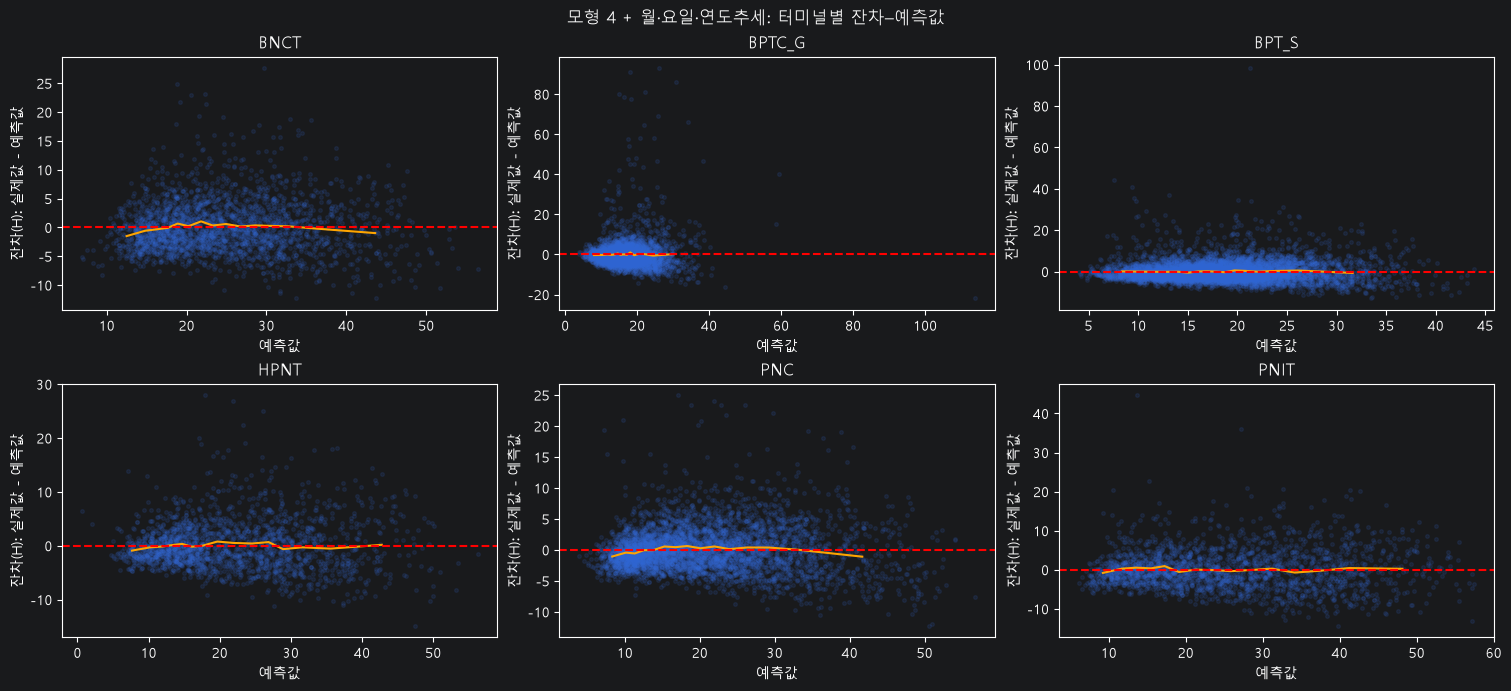

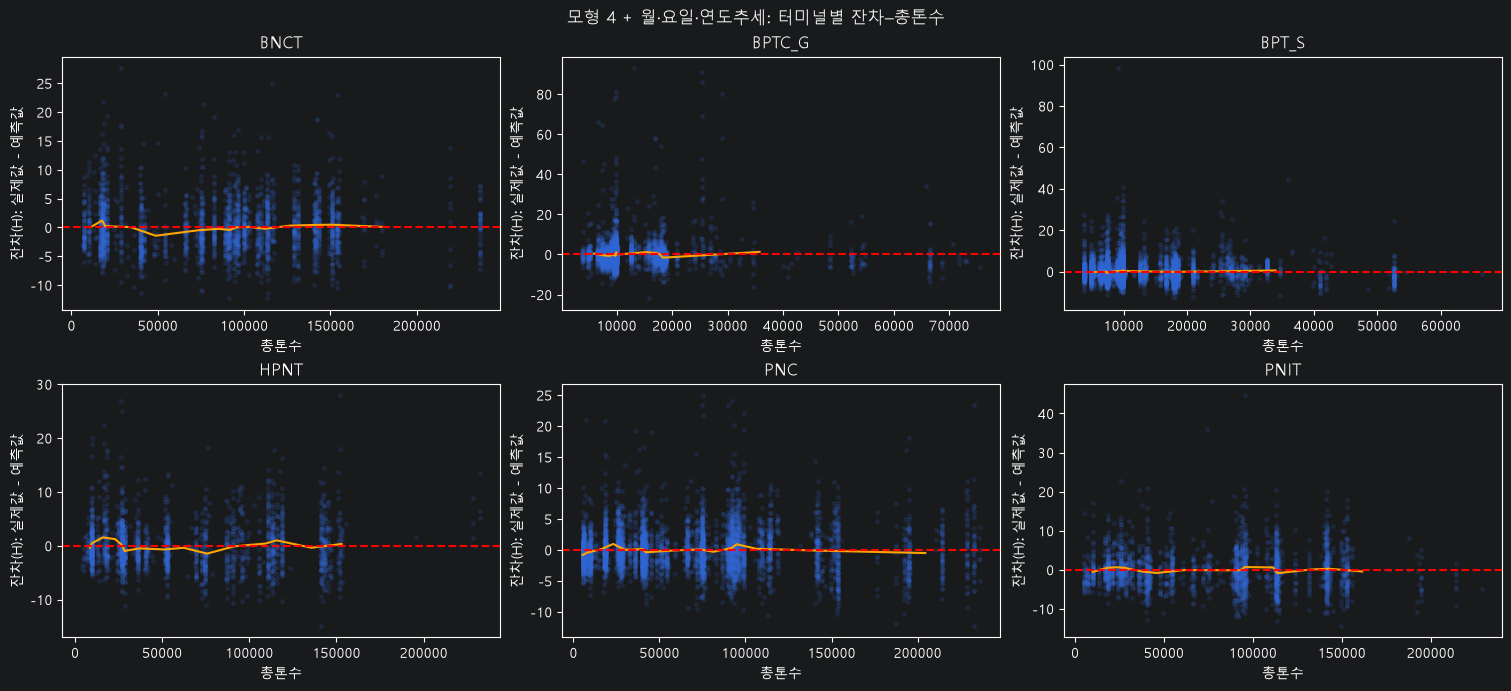

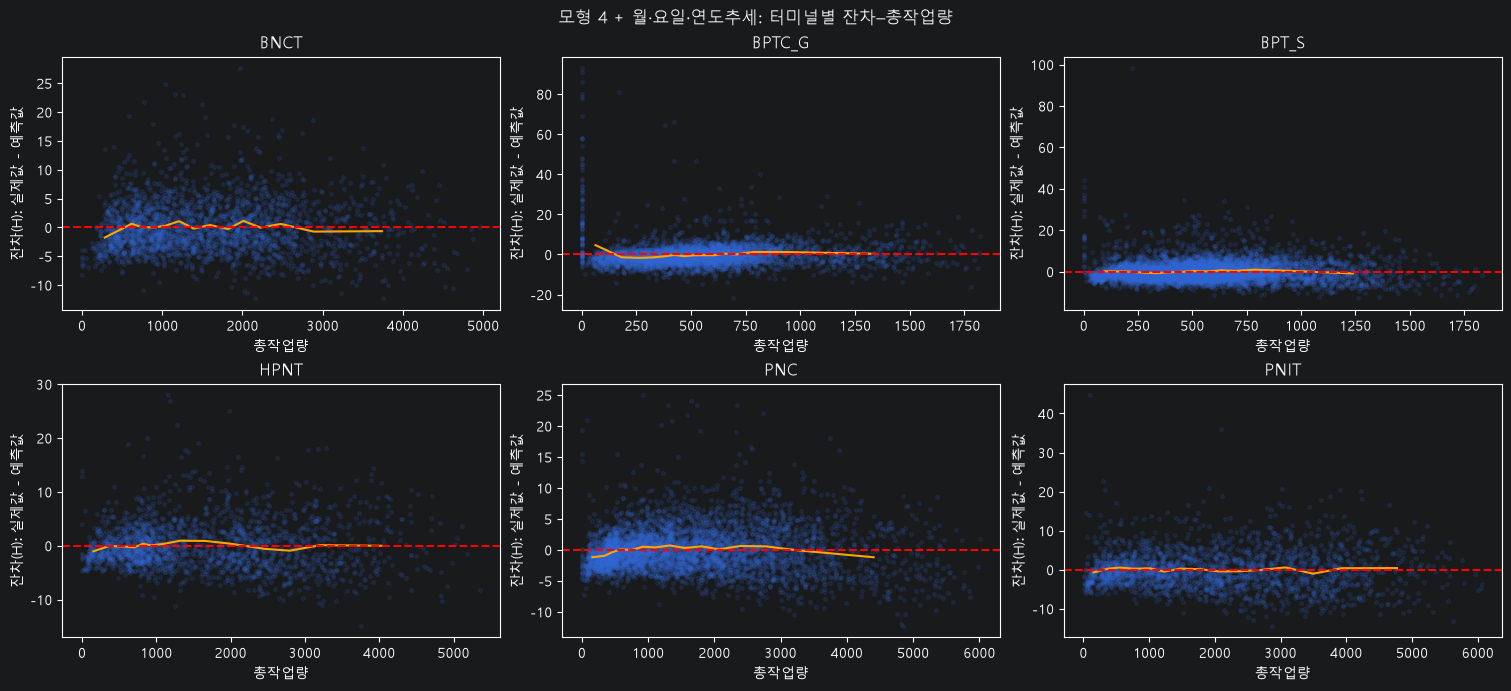

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


diagnosis = df_train[["항만구분", "터미널", "접안일시"] + continuous_vars + [warning_col]].copy()
diagnosis["항만구분"] = diagnosis["항만구분"].astype("string").str.strip()
diagnosis["예측값"] = np.asarray(final_model.fittedvalues)
diagnosis["잔차"] = np.asarray(final_model.resid)
DRAW_EACH_X = True
residual_bin_rows = []

for group_column in ["터미널", "항만구분"]:
    groups = list(diagnosis.groupby(group_column, sort=False, observed=True))
    for variable in ["예측값"] + (continuous_vars if DRAW_EACH_X else []):
        columns = min(3, len(groups))
        rows = (len(groups) + columns - 1) // columns
        fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 3.4 * rows),
                                 squeeze=False, layout="constrained")
        for ax, (label, part) in zip(axes.ravel(), groups):
            ax.scatter(part[variable], part["잔차"], s=7, alpha=.12, rasterized=True)
            if part[variable].nunique() >= 2:
                bins = pd.qcut(part[variable], q=min(15, part[variable].nunique()), duplicates="drop")
                trend = part.groupby(bins, observed=True).agg(
                    X평균=(variable, "mean"), 평균잔차=("잔차", "mean"),
                    잔차표준편차=("잔차", "std"), 표본수=("잔차", "size"))
                ax.plot(trend["X평균"], trend["평균잔차"], color="orange")
                for interval, row in trend.iterrows():
                    residual_bin_rows.append({"구분": group_column, "집단": label,
                        "변수": variable, "구간": str(interval), **row.to_dict()})
            ax.axhline(0, color="red", linestyle="--")
            ax.set(title=str(label), xlabel=variable, ylabel="잔차(H): 실제값 - 예측값")
        for ax in axes.ravel()[len(groups):]:
            ax.set_visible(False)
        fig.suptitle(f"{FINAL_MODEL_NAME}: {group_column}별 잔차–{variable}")
        plt.show()

residual_bin_counts = pd.DataFrame(residual_bin_rows)
print("잔차 구간 중 표본 수가 적은 구간 — 곡선 해석 시 함께 확인")
display(residual_bin_counts.sort_values("표본수").head(30).round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 7), layout="constrained")
for ax, terminal in zip(axes.ravel(), TERMINALS):
    part = diagnosis.loc[diagnosis["터미널"].eq(terminal)]
    sm.qqplot(part["잔차"].to_numpy(), line="45", fit=True, ax=ax)
    ax.set_title(terminal)
fig.suptitle(f"{FINAL_MODEL_NAME}: 터미널별 정규 Q–Q 그래프")
plt.show()

daily_correlation_rows = []
for group_column in ["터미널", "항만구분"]:
    daily = diagnosis.assign(접안일=diagnosis["접안일시"].dt.normalize()).groupby(
        [group_column, "접안일"], observed=True)["잔차"].mean()
    for label in daily.index.get_level_values(0).unique():
        series = daily.loc[label].asfreq("D")
        for lag in [1, 7, 14, 28]:
            pairs = pd.concat([series, series.shift(lag)], axis=1).dropna()
            daily_correlation_rows.append({"구분": group_column, "집단": label,
                "시차(일)": lag, "날짜 쌍 수": len(pairs),
                "잔차 상관": series.corr(series.shift(lag)) if len(pairs) > 2 else np.nan})
daily_correlation_table = pd.DataFrame(daily_correlation_rows)
display(daily_correlation_table.round(3))

annual_residual_table = diagnosis.assign(접안연도=diagnosis["접안일시"].dt.year).groupby(
    ["터미널", "접안연도"], observed=True)["잔차"].agg(표본수="size", 평균잔차="mean", 잔차표준편차="std")
display(annual_residual_table.round(3))


### 큰 파고 구간의 표본 수

각 파고변수의 학습 95% 분위값 이상을 큰 값 구간으로 표시하고 학습·검증의 항만·터미널별 표본 수와 잔차를 확인합니다.
동점 때문에 정확히 상위 5%와 일치하지 않을 수 있습니다. 관측이 적은 구간의 곡선·효과를 과도하게 일반화하지 않습니다.


In [57]:
wave_variables = [c for c in weather_vars if "파고" in c]
wave_thresholds = {c: float(df_train[c].quantile(.95)) for c in wave_variables}
weather_support_rows = []
for label, frame, residual in [
    ("학습", df_train, np.asarray(final_model.resid)),
    ("검증", df_valid, y_valid.to_numpy() - np.asarray(final_model.predict(valid_designs[FINAL_MODEL_NAME]))),
]:
    source = frame[["항만구분", "터미널"] + wave_variables].copy()
    source["항만구분"] = source["항만구분"].astype("string").str.strip()
    source["잔차(H)"] = residual
    for variable in wave_variables:
        for group_column in ["항만구분", "터미널"]:
            for group_label, group in source.groupby(group_column, observed=True):
                tail = group.loc[group[variable].ge(wave_thresholds[variable])]
                weather_support_rows.append({"자료": label, "구분": group_column, "집단": group_label,
                    "변수": variable, "학습 95% 분위값(m)": wave_thresholds[variable],
                    "전체 표본 수": len(group), "큰 값 구간 표본 수": len(tail),
                    "큰 값 구간 비율(%)": len(tail) / len(group) * 100,
                    "큰 값 구간 평균잔차(H)": tail["잔차(H)"].mean() if len(tail) else np.nan})
weather_support_counts = pd.DataFrame(weather_support_rows)
display(weather_support_counts.round(3))


,자료,구분,집단,변수,학습 95% 분위값(m),전체 표본 수,큰 값 구간 표본 수,큰 값 구간 비율(%),큰 값 구간 평균잔차(H)
0,학습,항만구분,북항,체류시간_유의파고_중앙값_m,1.1,11942,1253,10.492,-0.036
1,학습,항만구분,신항,체류시간_유의파고_중앙값_m,1.1,11615,161,1.386,-0.051
2,학습,터미널,BNCT,체류시간_유의파고_중앙값_m,1.1,2470,40,1.619,-1.143
3,학습,터미널,BPTC_G,체류시간_유의파고_중앙값_m,1.1,4281,445,10.395,-0.054
4,학습,터미널,BPT_S,체류시간_유의파고_중앙값_m,1.1,7661,808,10.547,-0.027
5,학습,터미널,HPNT,체류시간_유의파고_중앙값_m,1.1,2030,23,1.133,-0.749
6,학습,터미널,PNC,체류시간_유의파고_중앙값_m,1.1,4855,73,1.504,0.774
7,학습,터미널,PNIT,체류시간_유의파고_중앙값_m,1.1,2260,25,1.106,-0.071
8,학습,항만구분,북항,체류시간_순간최대파고_최댓값_m,2.4,11942,1006,8.424,-0.032
9,학습,항만구분,신항,체류시간_순간최대파고_최댓값_m,2.4,11615,223,1.920,-0.430


## 13. BP·White 검정 — 평가 대상 확장 모형

상호작용 확대 후 전체 White 제곱·교차항을 한꺼번에 만들면 불필요한 중복과 메모리 사용이 큽니다.
BP는 전체 설명변수로, White는 터미널 내부의 비중복 설명변수로 수행합니다.
White의 제곱·교차항은 QR 분해로 중복을 제거합니다.
터미널별 White 검정은 전체 모형에 대한 단일 검정과 구분해 표시합니다.
BP·White의 통상 p값은 자기상관을 별도로 보정하지 않으므로 그래프와 함께 참고합니다.



In [58]:
from scipy.linalg import qr
from scipy.stats import chi2
from statsmodels.stats.diagnostic import het_breuschpagan

X_diag = train_designs[FINAL_MODEL_NAME]
varying = X_diag.drop(columns="const")
Z = (varying - varying.mean()) / varying.std(ddof=0)
bp = het_breuschpagan(np.asarray(final_model.resid), sm.add_constant(Z), robust=False)
hetero_rows = [{"검정": "BP", "범위": "전체", "LM 통계량": bp[0], "p값": bp[1]}]

for terminal in TERMINALS:
    mask = df_train["터미널"].eq(terminal)
    # 터미널 안에서 더미·더미 곱항은 원래 항과 같거나 0이므로 제외
    columns = [c for c in X_diag if c != "const" and not c.startswith("터미널_")]
    local = X_diag.loc[mask, columns]
    local = local.loc[:, local.std(ddof=0) > 1e-12]
    local = (local - local.mean()) / local.std(ddof=0)
    base = sm.add_constant(local, has_constant="add").to_numpy()
    i, j = np.triu_indices(base.shape[1])
    terms = base[:, i] * base[:, j]
    std = terms.std(axis=0)
    terms = terms[:, std > 1e-12]
    terms = (terms - terms.mean(axis=0)) / terms.std(axis=0)
    R, order = qr(terms, mode="r", pivoting=True)
    tolerance = np.finfo(float).eps * max(terms.shape) * abs(R[0, 0])
    rank = int((np.abs(np.diag(R)) > tolerance).sum())
    if int(mask.sum()) <= rank + 1:
        hetero_rows.append({"검정": "White", "범위": terminal,
                            "LM 통계량": np.nan, "p값": np.nan})
        continue
    aux = sm.OLS(np.asarray(final_model.resid)[mask.to_numpy()] ** 2,
                 sm.add_constant(terms[:, order[:rank]], has_constant="add")).fit()
    lm = float(aux.nobs * aux.rsquared)
    hetero_rows.append({"검정": "White", "범위": terminal,
                        "LM 통계량": lm, "p값": chi2.sf(lm, aux.df_model)})

hetero_result = pd.DataFrame(hetero_rows)
hetero_result["5% 기준"] = hetero_result["p값"].map(
    lambda p: "계산 불가" if pd.isna(p) else "등분산성 기각" if p < .05 else "기각 못함"
)
display(hetero_result.style.format({"LM 통계량": "{:.3f}", "p값": "{:.4g}"}))


,검정,범위,LM 통계량,p값,5% 기준
0,BP,전체,49538.663,0,등분산성 기각
1,White,BPT_S,1666.158,1.346e-181,등분산성 기각
2,White,PNC,929.587,1.766e-61,등분산성 기각
3,White,BPTC_G,1848.069,5.076e-214,등분산성 기각
4,White,BNCT,470.915,4.166e-08,등분산성 기각
5,White,PNIT,434.957,1.169e-05,등분산성 기각
6,White,HPNT,615.424,2.429e-21,등분산성 기각


## 14. 확장 후 전체·터미널별 VIF

새 곱항을 포함해 다시 계산합니다. 터미널 내부에서는 더미항을 제외하되 규모×기상·특보 곱항은 유지합니다.
상호작용을 포함한 VIF가 높다는 이유만으로 하위 주효과를 자동 삭제하지 않습니다.


VIF>10 또는 Q–Q 꼬리 이탈만으로 후보를 자동 탈락시키지 않습니다.
조건부 평균의 패턴, 같은 검증자료의 주요 집단 오차, KPI 구간·민감도와 함께 해석합니다.


In [59]:
from scipy.linalg import solve_triangular


def design_vif(X):
    values = X.loc[:, X.nunique() > 1].astype(float)
    z = ((values - values.mean()) / values.std(ddof=0)).to_numpy()
    _, R = np.linalg.qr(z, mode="reduced")
    if R.shape[0] < R.shape[1] or np.linalg.matrix_rank(R) < R.shape[1]:
        raise ValueError("VIF 대상 열에 완전한 선형 중복이 있습니다.")
    inverse_R = solve_triangular(R, np.eye(R.shape[0]))
    vif = len(values) * np.sum(inverse_R ** 2, axis=1)
    return pd.Series(vif, index=values.columns, name="VIF").sort_values(ascending=False)


expanded_vif = design_vif(train_designs[FINAL_MODEL_NAME])
print("전체 설계의 VIF 상위 30개")
display(expanded_vif.head(30).round(3).to_frame())
local_columns = [c for c in train_designs[FINAL_MODEL_NAME]
                 if c != "const" and not c.startswith("터미널_")]
terminal_vif = pd.DataFrame({
    terminal: design_vif(train_designs[FINAL_MODEL_NAME].loc[
        df_train["터미널"].eq(terminal), local_columns
    ]) for terminal in TERMINALS
})
print("터미널 내부의 기본 변수와 규모×특보·기상 곱항 VIF")
display(terminal_vif.round(3))


전체 설계의 VIF 상위 30개


,VIF
총톤수,169.678
터미널_PNC:총톤수,105.988
터미널_BNCT:총톤수,78.232
터미널_PNIT:총톤수,63.114
총작업량,60.480
터미널_PNC:총작업량,48.501
터미널_HPNT:총톤수,42.856
터미널_PNIT:총작업량,37.433
터미널_HPNT:총작업량,25.884
터미널_BNCT:총작업량,25.645


터미널 내부의 기본 변수와 규모×특보·기상 곱항 VIF


,BPT_S,PNC,BPTC_G,BNCT,PNIT,HPNT
연도추세,1.143,1.131,1.157,1.147,1.109,1.132
요일_1,1.662,1.721,1.715,1.677,1.731,1.717
요일_2,1.670,1.778,1.724,1.761,1.820,1.850
요일_3,1.641,1.823,1.714,1.701,1.857,1.837
요일_4,1.657,1.768,1.673,1.644,1.771,1.921
요일_5,1.699,1.841,1.742,1.711,1.872,1.905
요일_6,1.693,1.831,1.771,1.709,1.811,1.827
월_10,2.537,2.398,2.613,2.329,2.387,2.518
월_11,2.430,2.320,2.545,2.305,2.232,2.573
월_12,2.386,2.240,2.439,2.217,2.231,2.365


## 15. 계산과 자료 분리의 일치 확인

계산 일치 검사는 코드 오류를 점검합니다. 실제 반사실 증가시간의 정확성을 입증하지는 않습니다.


In [60]:
assert list(prediction_models) == EXPECTED_MODEL_NAMES
assert df_train.index.intersection(df_valid.index).empty
assert (df_train["출항일시"] < CUTOFF).all()
assert (df_valid["접안일시"] >= CUTOFF).all()

time_to_base = {
    "모형 4 + 월·요일·연도추세": "모형 4",
    "모형 4 확장 + 월·요일·연도추세": "모형 4 확장",
}
for name, model in prediction_models.items():
    assert model.model.data.row_labels.equals(df_train.index)
    pd.testing.assert_frame_equal(
        design_input(df_valid, name), valid_designs[name], check_exact=False
    )
    for frame, designs in [(df_train, train_designs), (df_valid, valid_designs)]:
        X = designs[name]
        time_columns = [c for c in X if c.startswith("월_") or c.startswith("요일_") or c == "연도추세"]
        if name in time_to_base:
            assert len(time_columns) == 18
            assert sum(c.startswith("월_") for c in time_columns) == 11
            assert sum(c.startswith("요일_") for c in time_columns) == 6
            assert X.columns.tolist().count("연도추세") == 1
            np.testing.assert_array_equal(X["연도추세"], frame["접안일시"].dt.year - TREND_BASE_YEAR)
            base = designs[time_to_base[name]]
            assert X.shape[1] == base.shape[1] + 18
            pd.testing.assert_frame_equal(X.drop(columns=time_columns).loc[:, base.columns], base)
        else:
            assert not time_columns

np.testing.assert_allclose(
    validation_kpi["총증가시간(H)"],
    validation_kpi["기상변화분(H)"] + validation_kpi["특보적용분(H)"], atol=1e-7,
)
np.testing.assert_allclose(
    pred_actual,
    pred_off + df_valid[warning_col].to_numpy() * (pred_on - pred_off), atol=1e-7,
)
test_row = reference_rows[TERMINALS[0]]
zero_case = calculate_kpi(
    TERMINALS[0], float(test_row["총톤수"]), float(test_row["총작업량"]),
    test_row[weather_vars].to_dict(), warning=0,
)
np.testing.assert_allclose(zero_case["총증가시간(H)"], 0, atol=1e-8)

time_columns = [c for c in total_contrast if c.startswith("월_") or c.startswith("요일_") or c == "연도추세"]
np.testing.assert_allclose(total_contrast[time_columns].to_numpy(), 0, atol=0)
np.testing.assert_allclose(warning_contrast[time_columns].to_numpy(), 0, atol=0)
print("7개 모형·5번/7번 시간항·학습검증 분리·KPI 계산 일치 확인 통과")


7개 모형·5번/7번 시간항·학습검증 분리·KPI 계산 일치 확인 통과


## 16. 최종 선택에 사용할 근거

1. 같은 검증자료의 전체·특보·항만·터미널 MAE와 RMSE를 확인합니다.
2. 평균잔차의 부호와 크기, 장기 체류 기록의 과소예측 양상을 함께 봅니다.
3. 정해진 공통 프로필의 특보 증가량이 모형·HAC 기간·학습기간·영향 항차에 얼마나 민감한지 봅니다.
4. 평균 관계에 뚜렷한 곡선이 남는지와 큰 기상값 구간의 표본 수를 확인합니다.
5. 차이가 작으면 더 단순한 모형을 우선 검토합니다. 통과 검정 개수로 순위를 만들지 않습니다.

사실적 체류시간 예측이 좋다고 특보 때문에 실제로 늘어난 시간이 직접 검증되는 것은 아닙니다.
KPI는 다른 조건을 고정한 **모형상 특보 시나리오 차이**로 제시하고 구간과 민감도를 함께 보고합니다.
장기 체류·이상기상 기록은 실제 사건일 수 있으므로 자동 삭제하지 않습니다.


In [61]:
# 검증 집단 정의가 모형마다 바뀌지 않았는지 확인
for view in group_specs:
    counts = group_validation_scores.loc[group_validation_scores["관점"].eq(view)].groupby("모형")["표본 수"].sum()
    np.testing.assert_array_equal(counts.to_numpy(), len(df_valid))
for name in prediction_models:
    cases = validation_case_results.loc[validation_case_results["모형"].eq(name)]
    assert cases.index.equals(common_validation_index)
    np.testing.assert_allclose(cases["잔차(H)"], cases["실제(H)"] - cases["예측(H)"])
assert np.isclose(long_stay_threshold, y_train.quantile(LONG_STAY_QUANTILE))
assert int(final_model.nobs) == len(df_train)
for (name, period), sensitivity_model in period_models.items():
    assert sensitivity_model.model.data.row_labels.isin(df_train.index).all()
    assert not sensitivity_model.model.data.row_labels.isin(df_valid.index).any()
for variable, value in wave_thresholds.items():
    assert np.isclose(value, df_train[variable].quantile(.95))
assert len(prediction_models) == 7
print("같은 검증 행·집단 정의·잔차 부호·학습기간 민감도·원래 표본 유지 확인 통과")


같은 검증 행·집단 정의·잔차 부호·학습기간 민감도·원래 표본 유지 확인 통과
